# CLAM-TR: CLAM with Top-K Selection and Spatial Retention
## Complete Training Pipeline for PANDA Dataset

**Experiments:**
| # | Encoder | Aggregation | Status |
|---|---------|-------------|--------|
| 1 | ResNet-50 | CLAM | Baseline |
| 2 | ResNet-50 | CLAM-TR | Baseline |
| 3 | UNI | CLAM | Best encoder |
| 4 | UNI | CLAM-TR | Best encoder |

**Dataset:** PANDA 600-slide subset (80/20 stratified split)

---
## Section 1: Setup & Configuration

In [ ]:
!pip install -q openslide-python timm scikit-learn pandas matplotlib seaborn tqdm
!apt-get install -q openslide-tools
!pip install -q transformers scikit-image

Reading package lists...
Building dependency tree...
Reading state information...
The following additional packages will be installed:
  libopenslide0
Suggested packages:
  libtiff-tools
The following NEW packages will be installed:
  libopenslide0 openslide-tools
0 upgraded, 2 newly installed, 0 to remove and 41 not upgraded.
Need to get 104 kB of archives.
After this operation, 297 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 libopenslide0 amd64 3.4.1+dfsg-5build1 [89.8 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 openslide-tools amd64 3.4.1+dfsg-5build1 [13.8 kB]
Fetched 104 kB in 1s (123 kB/s)
Selecting previously unselected package libopenslide0.
(Reading database ... 121689 files and directories currently installed.)
Preparing to unpack .../libopenslide0_3.4.1+dfsg-5build1_amd64.deb ...
Unpacking libopenslide0 (3.4.1+dfsg-5build1) ...
Selecting previously unselected package openslide-tools.
Preparing to u

In [ ]:
import os, json, time, random, shutil
from pathlib import Path
from datetime import datetime, timedelta
from typing import Dict, List, Tuple, Optional, Any
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm
from PIL import Image
import openslide
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score, accuracy_score, f1_score, roc_auc_score, confusion_matrix, precision_recall_fscore_support
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
drive.mount('/content/drive')
print('All imports successful!')

Mounted at /content/drive
All imports successful!


In [ ]:
CONFIG = {
    'original_slides': '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train_images/',
    'ground_truth_masks': '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train_label_masks/',
    'subset_folder': '/content/drive/MyDrive/PANDA_Subset_600/images/',
    'preprocessing_dir': '/content/drive/MyDrive/CLAM_TR_Preprocessing/',
    'features_dir': '/content/drive/MyDrive/CLAM_TR_Features/',
    'checkpoints_dir': '/content/drive/MyDrive/CLAM_TR_Checkpoints/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/',
    'csv_path': '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train.csv',
    'patch_size': 256, 'magnification': '20x', 'feature_dim': 1024, 'hidden_dim': 512,
    'n_classes': 6, 'dropout': 0.25, 'K': 128, 'num_heads': 8,
    'gamma_values': [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99],
    'epochs': 50, 'lr': 1e-4, 'weight_decay': 1e-5, 'label_smoothing': 0.1, 'seed': 42,
    'train_ratio': 0.8, 'val_ratio': 0.2,
    'checkpoint_freq_epochs': 5, 'checkpoint_freq_minutes': 30,
    'data_copy_checkpoint_freq': 50, 'preprocessing_checkpoint_freq': 100,
    'feature_extraction_checkpoint_freq': 100
}

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

set_seed(CONFIG['seed'])
print(f'Seeds set to {CONFIG["seed"]}')

Seeds set to 42


In [ ]:
# ============================================================================
# HUGGINGFACE AUTHENTICATION (Required for UNI encoder)
# ============================================================================
# Replace 'YOUR_HF_TOKEN_HERE' with your actual HuggingFace token
# Get your token at: https://huggingface.co/settings/tokens

import os
from huggingface_hub import login

HF_TOKEN = "hf_YOUR_HF_TOKEN_HERE"  # <-- REPLACE WITH YOUR TOKEN

# Set environment variable
os.environ["HF_TOKEN"] = HF_TOKEN
os.environ["HUGGINGFACE_HUB_TOKEN"] = HF_TOKEN

# Authenticate with HuggingFace
try:
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("HuggingFace authentication successful!")
    print("You can now access gated models like MahmoodLab/UNI")
except Exception as e:
    print(f"HuggingFace authentication failed: {e}")
    print("\nTo fix this:")
    print("1. Go to https://huggingface.co/settings/tokens")
    print("2. Create a new token with 'read' access")
    print("3. Replace 'YOUR_HF_TOKEN_HERE' with your token")
    print("4. Make sure you have access to MahmoodLab/UNI")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HuggingFace authentication successful!
You can now access gated models like MahmoodLab/UNI


In [ ]:
def detect_gpu_and_set_batch_size():
    if not torch.cuda.is_available():
        print('WARNING: No GPU detected!')
        return {'feature_extraction': 32, 'training': 1}
    gpu_name = torch.cuda.get_device_name(0).lower()
    gpu_memory = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'GPU: {torch.cuda.get_device_name(0)}, Memory: {gpu_memory:.1f} GB')
    if 'h100' in gpu_name or 'a100' in gpu_name:
        batch_sizes = {'feature_extraction': 512, 'training': 1}
    elif 'l4' in gpu_name:
        batch_sizes = {'feature_extraction': 256, 'training': 1}
    else:
        batch_sizes = {'feature_extraction': 128, 'training': 1}
    return batch_sizes

BATCH_SIZES = detect_gpu_and_set_batch_size()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

GPU: Tesla T4, Memory: 15.8 GB
Using device: cuda


In [ ]:
def create_directories():
    dirs = [CONFIG['subset_folder'], CONFIG['preprocessing_dir'],
            os.path.join(CONFIG['preprocessing_dir'], 'patches'),
            os.path.join(CONFIG['preprocessing_dir'], 'coordinates'),
            CONFIG['features_dir'],
            os.path.join(CONFIG['features_dir'], 'resnet50'),
            os.path.join(CONFIG['features_dir'], 'phikon_v2'),
            os.path.join(CONFIG['features_dir'], 'uni'),
            CONFIG['checkpoints_dir'], CONFIG['results_dir'],
            os.path.join(CONFIG['results_dir'], 'visualizations'),
            os.path.join(CONFIG['results_dir'], 'models')]
    for d in dirs: os.makedirs(d, exist_ok=True)
    print('All directories created!')
create_directories()

All directories created!


---
## Section 2: CheckpointManager Class

In [ ]:
class CheckpointManager:
    def __init__(self, checkpoint_dir):
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)
        self.progress_files = {
            'data_copy': os.path.join(checkpoint_dir, 'data_copy_progress.json'),
            'preprocessing': os.path.join(checkpoint_dir, 'preprocessing_progress.json'),
            'feature_extraction': os.path.join(checkpoint_dir, 'feature_extraction_progress.json'),
            'experiments': os.path.join(checkpoint_dir, 'experiment_progress.json')}

    def _save_json(self, filepath, data):
        for attempt in range(3):
            try:
                with open(filepath, 'w') as f: json.dump(data, f, indent=2)
                return
            except: time.sleep(1)

    def _load_json(self, filepath):
        if os.path.exists(filepath):
            try:
                with open(filepath, 'r') as f: return json.load(f)
            except: return {}
        return {}

    def get_copied_slides(self): return set(self._load_json(self.progress_files['data_copy']).get('copied_slides', []))
    def save_data_copy_progress(self, copied_slides):
        self._save_json(self.progress_files['data_copy'], {'copied_slides': list(copied_slides), 'count': len(copied_slides), 'last_updated': datetime.now().isoformat()})
    def get_preprocessed_slides(self): return set(self._load_json(self.progress_files['preprocessing']).get('preprocessed_slides', []))
    def save_preprocessing_progress(self, preprocessed_slides):
        self._save_json(self.progress_files['preprocessing'], {'preprocessed_slides': list(preprocessed_slides), 'count': len(preprocessed_slides), 'last_updated': datetime.now().isoformat()})
    def get_extracted_features(self, encoder): return set(self._load_json(self.progress_files['feature_extraction']).get(encoder, {}).get('extracted_slides', []))
    def save_feature_extraction_progress(self, encoder, extracted_slides):
        data = self._load_json(self.progress_files['feature_extraction'])
        data[encoder] = {'extracted_slides': list(extracted_slides), 'count': len(extracted_slides), 'last_updated': datetime.now().isoformat()}
        self._save_json(self.progress_files['feature_extraction'], data)
    def save_training_checkpoint(self, experiment_name, epoch, model_state, optimizer_state, scheduler_state, best_qwk, metrics_history):
        checkpoint_path = os.path.join(self.checkpoint_dir, f'{experiment_name}_checkpoint.pt')
        torch.save({'epoch': epoch, 'model_state_dict': model_state, 'optimizer_state_dict': optimizer_state, 'scheduler_state_dict': scheduler_state, 'best_qwk': best_qwk, 'metrics_history': metrics_history, 'timestamp': datetime.now().isoformat()}, checkpoint_path)
        return checkpoint_path
    def load_training_checkpoint(self, experiment_name):
        checkpoint_path = os.path.join(self.checkpoint_dir, f'{experiment_name}_checkpoint.pt')
        if os.path.exists(checkpoint_path):
            try: return torch.load(checkpoint_path, map_location=DEVICE)
            except: return None
        return None
    def get_completed_experiments(self): return self._load_json(self.progress_files['experiments'])
    def save_experiment_result(self, experiment_name, metrics, model_path):
        data = self._load_json(self.progress_files['experiments'])
        data[experiment_name] = {'metrics': metrics, 'model_path': model_path, 'completed_at': datetime.now().isoformat()}
        self._save_json(self.progress_files['experiments'], data)
    def is_experiment_completed(self, experiment_name): return experiment_name in self._load_json(self.progress_files['experiments'])

checkpoint_manager = CheckpointManager(CONFIG['checkpoints_dir'])
print('CheckpointManager initialized!')

CheckpointManager initialized!


---
## Section 3: Data Preparation (Copy 600 Slides)

In [ ]:
def prepare_subset_data():
    df = pd.read_csv(CONFIG['csv_path'])
    print(f'Total slides: {len(df)}')
    subset_dfs = [df[df['isup_grade'] == g].sample(n=100, random_state=CONFIG['seed']) for g in range(6)]
    subset_df = pd.concat(subset_dfs, ignore_index=True)
    print(f'Subset: {len(subset_df)} slides')
    subset_df.to_csv(os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv'), index=False)

    copied_slides = checkpoint_manager.get_copied_slides()
    slides_to_copy = [sid for sid in subset_df['image_id'].tolist() if sid not in copied_slides]
    print(f'Already copied: {len(copied_slides)}, To copy: {len(slides_to_copy)}')
    if len(slides_to_copy) == 0: return subset_df

    copied_list = list(copied_slides)
    for i, slide_id in enumerate(tqdm(slides_to_copy, desc='Copying')):
        src = os.path.join(CONFIG['original_slides'], f'{slide_id}.tiff')
        dst = os.path.join(CONFIG['subset_folder'], f'{slide_id}.tiff')
        if os.path.exists(dst): copied_list.append(slide_id); continue
        if not os.path.exists(src): continue
        try: shutil.copy2(src, dst); copied_list.append(slide_id)
        except: pass
        if (i + 1) % CONFIG['data_copy_checkpoint_freq'] == 0:
            checkpoint_manager.save_data_copy_progress(copied_list)
    checkpoint_manager.save_data_copy_progress(copied_list)
    return subset_df

subset_df = prepare_subset_data()

Total slides: 10616
Subset: 600 slides
Already copied: 600, To copy: 0


---
## Section 4: Preprocessing (Tissue Segmentation + Patch Extraction)

In [ ]:
from skimage.filters import threshold_otsu
from skimage.color import rgb2gray

class SlidePreprocessor:
    def __init__(self, patch_size=256, target_mag='20x', min_tissue_ratio=0.5):
        self.patch_size = patch_size
        self.target_mag = target_mag
        self.min_tissue_ratio = min_tissue_ratio

    def get_magnification_level(self, slide):
        try: obj_power = float(slide.properties.get('openslide.objective-power', 40))
        except: obj_power = 40
        target_power = 20 if self.target_mag == '20x' else 40
        downsample_needed = obj_power / target_power
        best_level, best_diff = 0, float('inf')
        for level in range(slide.level_count):
            diff = abs(slide.level_downsamples[level] - downsample_needed)
            if diff < best_diff: best_diff, best_level = diff, level
        return best_level

    def segment_tissue(self, slide):
        thumbnail = slide.get_thumbnail((1024, 1024))
        gray = rgb2gray(np.array(thumbnail))
        try: thresh = threshold_otsu(gray); tissue_mask = gray < thresh
        except: tissue_mask = gray < 0.8
        return tissue_mask.astype(np.uint8) * 255

    def extract_patches(self, slide, tissue_mask):
        level = self.get_magnification_level(slide)
        downsample = slide.level_downsamples[level]
        patch_size_l0 = int(self.patch_size * downsample)
        scale_x = tissue_mask.shape[1] / slide.level_dimensions[0][0]
        scale_y = tissue_mask.shape[0] / slide.level_dimensions[0][1]
        patches, coordinates = [], []
        for y in range(0, slide.level_dimensions[0][1] - patch_size_l0, patch_size_l0):
            for x in range(0, slide.level_dimensions[0][0] - patch_size_l0, patch_size_l0):
                mx, my = int(x * scale_x), int(y * scale_y)
                mw, mh = max(1, int(patch_size_l0 * scale_x)), max(1, int(patch_size_l0 * scale_y))
                mx, my = min(mx, tissue_mask.shape[1]-1), min(my, tissue_mask.shape[0]-1)
                mw, mh = min(mw, tissue_mask.shape[1]-mx), min(mh, tissue_mask.shape[0]-my)
                if mw <= 0 or mh <= 0: continue
                tissue_ratio = np.mean(tissue_mask[my:my+mh, mx:mx+mw] > 0)
                if tissue_ratio >= self.min_tissue_ratio:
                    try:
                        patch = slide.read_region((x, y), level, (self.patch_size, self.patch_size)).convert('RGB')
                        if np.mean(np.array(patch)) < 240:
                            patches.append(np.array(patch))
                            coordinates.append((x, y))
                    except: continue
        return patches, coordinates

    def process_slide(self, slide_path, output_dir, slide_id):
        try: slide = openslide.OpenSlide(slide_path)
        except: return 0
        tissue_mask = self.segment_tissue(slide)
        patches, coordinates = self.extract_patches(slide, tissue_mask)
        if len(patches) == 0: slide.close(); return 0
        patch_dir = os.path.join(output_dir, 'patches', slide_id)
        os.makedirs(patch_dir, exist_ok=True)
        for patch, (x, y) in zip(patches, coordinates):
            Image.fromarray(patch).save(os.path.join(patch_dir, f'patch_{x}_{y}.png'))
        pd.DataFrame(coordinates, columns=['x', 'y']).to_csv(os.path.join(output_dir, 'coordinates', f'{slide_id}_coords.csv'), index=False)
        slide.close()
        return len(patches)

preprocessor = SlidePreprocessor(patch_size=CONFIG['patch_size'], target_mag=CONFIG['magnification'])

In [ ]:
def run_preprocessing():
    slide_files = [f for f in os.listdir(CONFIG['subset_folder']) if f.endswith('.tiff')]
    slide_ids = [f.replace('.tiff', '') for f in slide_files]
    processed = checkpoint_manager.get_preprocessed_slides()
    to_process = [s for s in slide_ids if s not in processed]
    print(f'To process: {len(to_process)}/{len(slide_ids)}')
    if len(to_process) == 0: return
    processed_list = list(processed)
    for i, slide_id in enumerate(tqdm(to_process, desc='Preprocessing')):
        slide_path = os.path.join(CONFIG['subset_folder'], f'{slide_id}.tiff')
        patch_dir = os.path.join(CONFIG['preprocessing_dir'], 'patches', slide_id)
        if os.path.exists(patch_dir): processed_list.append(slide_id); continue
        try: preprocessor.process_slide(slide_path, CONFIG['preprocessing_dir'], slide_id); processed_list.append(slide_id)
        except: pass
        if (i + 1) % CONFIG['preprocessing_checkpoint_freq'] == 0:
            checkpoint_manager.save_preprocessing_progress(processed_list)
    checkpoint_manager.save_preprocessing_progress(processed_list)
run_preprocessing()

To process: 0/600


In [ ]:
# Check actual size of patches on Google Drive
import subprocess

patches_path = os.path.join(CONFIG['preprocessing_dir'], 'patches')
coords_path = os.path.join(CONFIG['preprocessing_dir'], 'coordinates')

# Get size
result = subprocess.run(['du', '-sh', patches_path], capture_output=True, text=True)
print(f"Patches folder size: {result.stdout.strip()}")

result = subprocess.run(['du', '-sh', coords_path], capture_output=True, text=True)
print(f"Coordinates folder size: {result.stdout.strip()}")

# Check local disk space
result = subprocess.run(['df', '-h', '/content'], capture_output=True, text=True)
print(f"\nLocal disk space:\n{result.stdout}")

Patches folder size: 28G	/content/drive/MyDrive/CLAM_TR_Preprocessing/patches
Coordinates folder size: 2.7M	/content/drive/MyDrive/CLAM_TR_Preprocessing/coordinates

Local disk space:
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   40G   74G  35% /



In [ ]:
# ============================================================================
# SPEED FIX: Copy patches to LOCAL disk (WITH PROGRESS BAR)
# ============================================================================
# Total to copy: ~28 GB patches + ~2.7 MB coordinates
# Your free space: 74 GB ✅ Enough!
# ============================================================================

import shutil
import os
from tqdm.auto import tqdm

LOCAL_PREPROCESSING = '/content/CLAM_TR_Preprocessing/'
SOURCE_DIR = CONFIG['preprocessing_dir']

print("="*60)
print("COPYING PATCHES TO LOCAL DISK FOR FASTER EXTRACTION")
print("="*60)
print(f"Source:      Google Drive ({SOURCE_DIR})")
print(f"Destination: Local disk ({LOCAL_PREPROCESSING})")
print(f"Size:        ~28 GB patches + ~2.7 MB coordinates")
print("="*60)

# Check if already copied
if os.path.exists(os.path.join(LOCAL_PREPROCESSING, 'patches')) and \
   len(os.listdir(os.path.join(LOCAL_PREPROCESSING, 'patches'))) > 500:
    num_slides = len(os.listdir(os.path.join(LOCAL_PREPROCESSING, 'patches')))
    print(f"✅ Already copied! Found {num_slides} slide folders")
else:
    # Remove partial copy if exists
    if os.path.exists(LOCAL_PREPROCESSING):
        print("Removing partial copy...")
        shutil.rmtree(LOCAL_PREPROCESSING)

    os.makedirs(LOCAL_PREPROCESSING, exist_ok=True)

    # =========================================================================
    # COPY PATCHES WITH PROGRESS BAR
    # =========================================================================
    print("\n📁 Copying patches folder (~28 GB)...")

    source_patches = os.path.join(SOURCE_DIR, 'patches')
    dest_patches = os.path.join(LOCAL_PREPROCESSING, 'patches')
    os.makedirs(dest_patches, exist_ok=True)

    # Get list of slide folders
    slide_folders = os.listdir(source_patches)
    total_slides = len(slide_folders)

    # Track progress
    total_copied_bytes = 0
    total_files_copied = 0

    # Copy each slide folder with progress
    for slide_id in tqdm(slide_folders, desc="Copying slides", unit="slide"):
        src_folder = os.path.join(source_patches, slide_id)
        dst_folder = os.path.join(dest_patches, slide_id)

        if os.path.isdir(src_folder):
            # Copy the slide folder
            shutil.copytree(src_folder, dst_folder)

            # Calculate size copied
            for root, dirs, files in os.walk(dst_folder):
                for f in files:
                    fp = os.path.join(root, f)
                    total_copied_bytes += os.path.getsize(fp)
                    total_files_copied += 1

        # Print progress every 50 slides
        if (slide_folders.index(slide_id) + 1) % 50 == 0:
            gb_copied = total_copied_bytes / (1024**3)
            print(f"   Progress: {gb_copied:.2f} GB copied ({total_files_copied:,} files)")

    # Final patches stats
    gb_copied = total_copied_bytes / (1024**3)
    print(f"\n✅ Patches copied: {gb_copied:.2f} GB ({total_files_copied:,} files)")

    # =========================================================================
    # COPY COORDINATES
    # =========================================================================
    print("\n📁 Copying coordinates folder (~2.7 MB)...")

    source_coords = os.path.join(SOURCE_DIR, 'coordinates')
    dest_coords = os.path.join(LOCAL_PREPROCESSING, 'coordinates')

    shutil.copytree(source_coords, dest_coords)

    coords_files = len(os.listdir(dest_coords))
    print(f"✅ Coordinates copied: {coords_files} files")

    # =========================================================================
    # FINAL SUMMARY
    # =========================================================================
    print("\n" + "="*60)
    print("✅ COPY COMPLETE!")
    print("="*60)
    print(f"Total copied:  {gb_copied:.2f} GB")
    print(f"Total files:   {total_files_copied:,} patch files + {coords_files} coordinate files")
    print(f"Slides:        {total_slides}")
    print("="*60)

# Update CONFIG to use local path
CONFIG['preprocessing_dir_original'] = CONFIG.get('preprocessing_dir_original', CONFIG['preprocessing_dir'])
CONFIG['preprocessing_dir'] = LOCAL_PREPROCESSING

# Verify local disk usage
import subprocess
result = subprocess.run(['df', '-h', '/content'], capture_output=True, text=True)
print(f"\n📊 Local disk status:")
print(result.stdout)

print(f"\n✅ Now using LOCAL path: {CONFIG['preprocessing_dir']}")
print("✅ Feature extraction will be 5-10x FASTER!")

COPYING PATCHES TO LOCAL DISK FOR FASTER EXTRACTION
Source:      Google Drive (/content/drive/MyDrive/CLAM_TR_Preprocessing/)
Destination: Local disk (/content/CLAM_TR_Preprocessing/)
Size:        ~28 GB patches + ~2.7 MB coordinates

📁 Copying patches folder (~28 GB)...


Copying slides:   0%|          | 0/600 [00:00<?, ?slide/s]

   Progress: 2.23 GB copied (18,940 files)
   Progress: 4.44 GB copied (37,977 files)
   Progress: 6.78 GB copied (57,356 files)
   Progress: 9.24 GB copied (78,284 files)
   Progress: 11.58 GB copied (99,548 files)
   Progress: 14.08 GB copied (121,677 files)
   Progress: 16.29 GB copied (141,895 files)
   Progress: 18.39 GB copied (161,240 files)
   Progress: 20.77 GB copied (182,252 files)
   Progress: 22.81 GB copied (200,030 files)
   Progress: 25.08 GB copied (221,438 files)
   Progress: 27.27 GB copied (241,954 files)

✅ Patches copied: 27.27 GB (241,954 files)

📁 Copying coordinates folder (~2.7 MB)...
✅ Coordinates copied: 600 files

✅ COPY COMPLETE!
Total copied:  27.27 GB
Total files:   241,954 patch files + 600 coordinate files
Slides:        600

📊 Local disk status:
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   76G   37G  68% /


✅ Now using LOCAL path: /content/CLAM_TR_Preprocessing/
✅ Feature extraction will be 5-10x FASTER!


---
## Section 5: Feature Extraction

In [ ]:
from torchvision import transforms
from huggingface_hub import hf_hub_download

class ResNet50Encoder(nn.Module):
    def __init__(self, output_dim=1024):
        super().__init__()
        resnet = timm.create_model('resnet50', pretrained=True)
        self.encoder = nn.Sequential(*list(resnet.children())[:-1])
        self.projection = nn.Linear(2048, output_dim)
        for p in self.encoder.parameters(): p.requires_grad = False

    def forward(self, x):
        return self.projection(self.encoder(x).flatten(1))

class UNIEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        # UNI uses ViT-L/16 with LayerScale (init_values enables ls1/ls2 gamma parameters)
        self.encoder = timm.create_model(
            "vit_large_patch16_224",
            img_size=224,
            patch_size=16,
            init_values=1e-5,  # Enable LayerScale
            num_classes=0,
            dynamic_img_size=True
        )
        # Download and load pretrained weights from HuggingFace
        weights_path = hf_hub_download("MahmoodLab/UNI", "pytorch_model.bin")
        self.encoder.load_state_dict(torch.load(weights_path, map_location="cpu"), strict=True)

        for p in self.encoder.parameters(): p.requires_grad = False
        print("UNI encoder loaded successfully (ViT-L/16 with LayerScale, 1024-dim)")

    def forward(self, x):
        return self.encoder(x)

In [ ]:
class FeatureExtractor:
    def __init__(self, encoder_name, batch_size=128):
        self.batch_size = batch_size
        self.encoder_name = encoder_name

        if encoder_name == 'resnet50':
            self.encoder = ResNet50Encoder(CONFIG['feature_dim'])
            print("ResNet-50 encoder loaded (2048->1024 projection)")
        elif encoder_name == 'uni':
            self.encoder = UNIEncoder()
        else:
            raise ValueError(f"Unknown encoder: {encoder_name}. Use 'resnet50' or 'uni'")

        self.encoder = self.encoder.to(DEVICE).eval()
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def extract_slide_features(self, slide_id, patches_dir, coords_path):
        coords_df = pd.read_csv(coords_path)
        patches, valid_coords = [], []
        for _, row in coords_df.iterrows():
            patch_path = os.path.join(patches_dir, f"patch_{row['x']}_{row['y']}.png")
            if os.path.exists(patch_path):
                try:
                    patches.append(self.transform(Image.open(patch_path).convert('RGB')))
                    valid_coords.append([row['x'], row['y']])
                except: continue
        if len(patches) == 0: return None, None
        patches_tensor = torch.stack(patches)
        all_features = []
        with torch.no_grad():
            for i in range(0, len(patches_tensor), self.batch_size):
                batch = patches_tensor[i:i+self.batch_size].to(DEVICE)
                features = self.encoder(batch).cpu()
                all_features.append(features)
                if torch.cuda.is_available(): torch.cuda.empty_cache()
        return torch.cat(all_features, dim=0), torch.tensor(valid_coords, dtype=torch.float32)

In [ ]:
def run_feature_extraction(encoder_name):
    print(f'\n{"="*60}')
    print(f'Feature Extraction: {encoder_name}')
    print(f'{"="*60}')

    # Create output directory
    output_dir = os.path.join(CONFIG['features_dir'], encoder_name)
    os.makedirs(output_dir, exist_ok=True)

    # Initialize extractor
    try:
        extractor = FeatureExtractor(encoder_name, BATCH_SIZES['feature_extraction'])
    except Exception as e:
        print(f'ERROR initializing encoder: {e}')
        import traceback
        traceback.print_exc()
        return

    # Get slides to process
    coords_dir = os.path.join(CONFIG['preprocessing_dir'], 'coordinates')
    slide_ids = [f.replace('_coords.csv', '') for f in os.listdir(coords_dir) if f.endswith('_coords.csv')]
    extracted = checkpoint_manager.get_extracted_features(encoder_name)
    to_extract = [s for s in slide_ids if s not in extracted]

    print(f'Already extracted: {len(extracted)}/{len(slide_ids)}')
    print(f'To extract: {len(to_extract)}')

    if len(to_extract) == 0:
        print('Nothing to extract!')
        return

    extracted_list = list(extracted)
    success_count = 0
    error_count = 0

    for i, slide_id in enumerate(tqdm(to_extract, desc=encoder_name)):
        feature_path = os.path.join(output_dir, f'{slide_id}.pt')

        # Skip if already exists
        if os.path.exists(feature_path):
            extracted_list.append(slide_id)
            success_count += 1
            continue

        patches_dir = os.path.join(CONFIG['preprocessing_dir'], 'patches', slide_id)
        coords_path = os.path.join(coords_dir, f'{slide_id}_coords.csv')

        try:
            features, coords = extractor.extract_slide_features(slide_id, patches_dir, coords_path)
            if features is not None:
                torch.save({'features': features, 'coordinates': coords}, feature_path)
                extracted_list.append(slide_id)
                success_count += 1
            else:
                print(f'\nWarning: No features extracted for {slide_id}')
                error_count += 1
        except Exception as e:
            print(f'\nERROR processing {slide_id}: {e}')
            error_count += 1

        # Checkpoint progress
        if (i + 1) % CONFIG['feature_extraction_checkpoint_freq'] == 0:
            checkpoint_manager.save_feature_extraction_progress(encoder_name, extracted_list)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    # Final save
    checkpoint_manager.save_feature_extraction_progress(encoder_name, extracted_list)

    print(f'\n{"="*60}')
    print(f'Feature Extraction Complete: {encoder_name}')
    print(f'  Success: {success_count}')
    print(f'  Errors: {error_count}')
    print(f'  Total saved: {len(os.listdir(output_dir))} files')
    print(f'{"="*60}')

    # Cleanup
    del extractor
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [ ]:
# Run feature extraction for ResNet-50 (baseline encoder)
print("="*60)
print("FEATURE EXTRACTION: ResNet-50")
print("="*60)
run_feature_extraction('resnet50')

FEATURE EXTRACTION: ResNet-50

Feature Extraction: resnet50


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

ResNet-50 encoder loaded (2048->1024 projection)
Already extracted: 600/600
To extract: 0
Nothing to extract!


In [ ]:
# Run feature extraction for UNI (best pathology encoder)
print("="*60)
print("FEATURE EXTRACTION: UNI")
print("="*60)
run_feature_extraction('uni')

print("\nFeature extraction complete!")

FEATURE EXTRACTION: UNI

Feature Extraction: uni


pytorch_model.bin:   0%|          | 0.00/1.21G [00:00<?, ?B/s]

UNI encoder loaded successfully (ViT-L/16 with LayerScale, 1024-dim)
Already extracted: 600/600
To extract: 0
Nothing to extract!

Feature extraction complete!


In [ ]:
# ============================================================================
# VERIFY FEATURE FILES BEFORE TRAINING
# ============================================================================

print("="*60)
print("VERIFYING FEATURE FILES")
print("="*60)

resnet_dir = os.path.join(CONFIG['features_dir'], 'resnet50')
uni_dir = os.path.join(CONFIG['features_dir'], 'uni')

resnet_count = len([f for f in os.listdir(resnet_dir) if f.endswith('.pt')]) if os.path.exists(resnet_dir) else 0
uni_count = len([f for f in os.listdir(uni_dir) if f.endswith('.pt')]) if os.path.exists(uni_dir) else 0

print(f"\nResNet-50 features: {resnet_count}/600 slides")
print(f"UNI features:       {uni_count}/600 slides")

# Check sample file format
if resnet_count > 0:
    sample_file = os.path.join(resnet_dir, os.listdir(resnet_dir)[0])
    data = torch.load(sample_file, map_location='cpu')
    print(f"\nResNet-50 sample: {data['features'].shape} features, {data['coordinates'].shape} coords")

if uni_count > 0:
    sample_file = os.path.join(uni_dir, [f for f in os.listdir(uni_dir) if f.endswith('.pt')][0])
    data = torch.load(sample_file, map_location='cpu')
    print(f"UNI sample: {data['features'].shape} features, {data['coordinates'].shape} coords")

print("\n" + "="*60)
if resnet_count >= 600 and uni_count >= 600:
    print("ALL FEATURES READY! Proceed to training.")
elif resnet_count >= 600:
    print("ResNet-50 ready. UNI extraction needed.")
    print("Run: run_feature_extraction('uni')")
else:
    print("Feature extraction incomplete.")
    print("Run: run_feature_extraction('resnet50')")
    print("Run: run_feature_extraction('uni')")
print("="*60)

VERIFYING FEATURE FILES

ResNet-50 features: 600/600 slides
UNI features:       600/600 slides

ResNet-50 sample: torch.Size([351, 1024]) features, torch.Size([351, 2]) coords
UNI sample: torch.Size([355, 1024]) features, torch.Size([355, 2]) coords

ALL FEATURES READY! Proceed to training.


---
## Section 6: Model Definitions

In [ ]:
# CLAM Model (Baseline)
class GatedAttention(nn.Module):
    def __init__(self, input_dim=1024, hidden_dim=512, dropout=0.25):
        super().__init__()
        self.attention_a = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.Tanh(), nn.Dropout(dropout))
        self.attention_b = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.Sigmoid(), nn.Dropout(dropout))
        self.attention_c = nn.Linear(hidden_dim, 1)
    def forward(self, x): return self.attention_c(self.attention_a(x) * self.attention_b(x)).squeeze(-1)

class CLAM(nn.Module):
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6, dropout=0.25):
        super().__init__()
        self.feature_transform = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.attention = GatedAttention(hidden_dim, hidden_dim // 2, dropout)
        self.classifier = nn.Linear(hidden_dim, n_classes)
    def forward(self, x, coords=None, return_attention=False):
        h = self.feature_transform(x)
        A = F.softmax(self.attention(h), dim=0)
        M = torch.sum(A.unsqueeze(-1) * h, dim=0)
        logits = self.classifier(M)
        return (logits, A) if return_attention else logits

In [ ]:
# CLAM-TR Model (Ours)
class SpatialRetentionHead(nn.Module):
    def __init__(self, hidden_dim, gamma=0.9):
        super().__init__()
        self.gamma = gamma
        self.head_dim = hidden_dim // 8
        self.W_Q = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_K = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_V = nn.Linear(hidden_dim, self.head_dim, bias=False)
    def forward(self, x, coords):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)
        diff = coords.unsqueeze(0) - coords.unsqueeze(1)
        distances = torch.norm(diff.float(), dim=-1)
        D = self.gamma ** (distances / (distances.max() + 1e-6))
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.head_dim ** 0.5) * D
        return torch.matmul(F.softmax(scores, dim=-1), V)

class SpatialRetention(nn.Module):
    def __init__(self, hidden_dim=512, num_heads=8, gamma_values=None):
        super().__init__()
        if gamma_values is None: gamma_values = [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99]
        self.heads = nn.ModuleList([SpatialRetentionHead(hidden_dim, gamma_values[i]) for i in range(num_heads)])
        self.output_proj = nn.Linear(hidden_dim, hidden_dim)
    def forward(self, x, coords): return self.output_proj(torch.cat([h(x, coords) for h in self.heads], dim=-1))

class CLAM_TR(nn.Module):
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6, dropout=0.25, K=128, num_heads=8, gamma_values=None):
        super().__init__()
        self.K = K
        self.feature_transform = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout))
        self.attention = GatedAttention(hidden_dim, hidden_dim // 2, dropout)
        self.spatial_retention = SpatialRetention(hidden_dim, num_heads, gamma_values)
        self.classifier = nn.Linear(hidden_dim, n_classes)
    def forward(self, x, coords, return_attention=False):
        h = self.feature_transform(x)
        A = self.attention(h)
        A_softmax = F.softmax(A, dim=0)
        K_actual = min(self.K, h.size(0))
        topk_indices = torch.topk(A, K_actual).indices
        h_topk, coords_topk, A_topk = h[topk_indices], coords[topk_indices], A_softmax[topk_indices]
        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)
        M_retention = torch.mean(self.spatial_retention(h_topk, coords_topk), dim=0)
        logits = self.classifier(M_clam + M_retention)
        if return_attention:
            full_attn = torch.zeros_like(A_softmax); full_attn[topk_indices] = A_topk
            return logits, full_attn, topk_indices
        return logits

print('CLAM and CLAM-TR models defined!')

CLAM and CLAM-TR models defined!


---
## Section 7: Dataset & DataLoader

In [ ]:
class PANDAFeatureDataset(Dataset):
    def __init__(self, slide_ids, labels, features_dir):
        self.slide_ids = slide_ids
        self.labels = labels
        self.features_dir = features_dir
    def __len__(self): return len(self.slide_ids)
    def __getitem__(self, idx):
        data = torch.load(os.path.join(self.features_dir, f'{self.slide_ids[idx]}.pt'), map_location='cpu')
        return data['features'], data['coordinates'], self.labels[idx], self.slide_ids[idx]

def collate_fn(batch): return batch[0][0], batch[0][1], batch[0][2], batch[0][3]

def create_dataloaders(encoder_name):
    subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)
    features_dir = os.path.join(CONFIG['features_dir'], encoder_name)

    # Check if features directory exists and has files
    if not os.path.exists(features_dir):
        print(f'ERROR: Features directory not found: {features_dir}')
        return None, None, None, None

    available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))

    if len(available) == 0:
        print(f'ERROR: No feature files found in {features_dir}')
        return None, None, None, None

    df = df[df['image_id'].isin(available)].reset_index(drop=True)

    if len(df) < 10:
        print(f'ERROR: Not enough samples ({len(df)}) for training with {encoder_name}')
        return None, None, None, None

    train_df, val_df = train_test_split(df, test_size=CONFIG['val_ratio'], stratify=df['isup_grade'], random_state=CONFIG['seed'])
    print(f'{encoder_name}: Train={len(train_df)}, Val={len(val_df)}')
    train_ds = PANDAFeatureDataset(train_df['image_id'].tolist(), train_df['isup_grade'].tolist(), features_dir)
    val_ds = PANDAFeatureDataset(val_df['image_id'].tolist(), val_df['isup_grade'].tolist(), features_dir)
    return DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn), DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn), train_df, val_df

---
## Section 8: Training Functions

In [ ]:
class LabelSmoothingLoss(nn.Module):
    def __init__(self, n_classes, smoothing=0.1):
        super().__init__()
        self.n_classes = n_classes
        self.smoothing = smoothing
    def forward(self, pred, target):
        confidence = 1.0 - self.smoothing
        smooth_label = self.smoothing / (self.n_classes - 1)
        one_hot = torch.zeros_like(pred).scatter(0, target.unsqueeze(0), 1)
        smooth_target = one_hot * confidence + (1 - one_hot) * smooth_label
        return -(smooth_target * F.log_softmax(pred, dim=0)).sum()

def train_one_epoch(model, loader, optimizer, criterion, device, model_type='clam'):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for features, coords, label, _ in tqdm(loader, desc='Train', leave=False):
        features, coords = features.to(device), coords.to(device)
        label = torch.tensor(label).to(device)
        optimizer.zero_grad()
        logits = model(features) if model_type == 'clam' else model(features, coords)
        loss = criterion(logits, label)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (logits.argmax() == label).item()
        total += 1
    return total_loss / total, correct / total

def validate(model, loader, criterion, device, model_type='clam'):
    model.eval()
    total_loss, preds, labels, probs = 0.0, [], [], []
    with torch.no_grad():
        for features, coords, label, _ in tqdm(loader, desc='Val', leave=False):
            features, coords = features.to(device), coords.to(device)
            label_t = torch.tensor(label).to(device)
            logits = model(features) if model_type == 'clam' else model(features, coords)
            total_loss += criterion(logits, label_t).item()
            preds.append(logits.argmax().cpu().item())
            labels.append(label)
            probs.append(F.softmax(logits, dim=0).cpu().numpy())
    return total_loss / len(loader), preds, labels, np.array(probs)

---
## Section 9: Metrics Calculation

In [ ]:
def calculate_metrics(y_true, y_pred, y_probs):
    metrics = {
        'qwk': cohen_kappa_score(y_true, y_pred, weights='quadratic'),
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'auc': roc_auc_score(y_true, y_probs, multi_class='ovr', average='macro') if len(np.unique(y_true)) > 1 else 0.0
    }
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None, labels=list(range(CONFIG['n_classes'])))
    metrics['per_class_f1'] = f1.tolist()
    metrics['confusion_matrix'] = confusion_matrix(y_true, y_pred).tolist()
    return metrics

def count_parameters(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [ ]:
def run_training(model, train_loader, val_loader, experiment_name, model_type='clam'):
    print(f'\n{"="*60}\nTraining: {experiment_name}\n{"="*60}')
    if checkpoint_manager.is_experiment_completed(experiment_name):
        print('Already completed!')
        return checkpoint_manager.get_completed_experiments()[experiment_name]['metrics']

    model = model.to(DEVICE)
    criterion = LabelSmoothingLoss(CONFIG['n_classes'], CONFIG['label_smoothing'])
    optimizer = Adam(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
    scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])

    checkpoint = checkpoint_manager.load_training_checkpoint(experiment_name)
    start_epoch, best_qwk = 0, -1
    metrics_history = {'train_loss': [], 'val_loss': [], 'val_qwk': [], 'val_acc': []}
    if checkpoint:
        print(f'Resuming from epoch {checkpoint["epoch"]}')
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        start_epoch, best_qwk = checkpoint['epoch'] + 1, checkpoint['best_qwk']
        metrics_history = checkpoint['metrics_history']

    last_ckpt_time = time.time()
    for epoch in range(start_epoch, CONFIG['epochs']):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE, model_type)
        val_loss, preds, labels, probs = validate(model, val_loader, criterion, DEVICE, model_type)
        qwk = cohen_kappa_score(labels, preds, weights='quadratic')
        acc = accuracy_score(labels, preds)
        metrics_history['train_loss'].append(train_loss)
        metrics_history['val_loss'].append(val_loss)
        metrics_history['val_qwk'].append(qwk)
        metrics_history['val_acc'].append(acc)
        print(f'Epoch {epoch+1}: Train Loss={train_loss:.4f}, Val QWK={qwk:.4f}, Val Acc={acc:.4f}')
        if qwk > best_qwk:
            best_qwk = qwk
            torch.save(model.state_dict(), os.path.join(CONFIG['results_dir'], 'models', f'{experiment_name}_best.pt'))
        scheduler.step()
        if (epoch + 1) % CONFIG['checkpoint_freq_epochs'] == 0 or (time.time() - last_ckpt_time) / 60 >= CONFIG['checkpoint_freq_minutes']:
            checkpoint_manager.save_training_checkpoint(experiment_name, epoch, model.state_dict(), optimizer.state_dict(), scheduler.state_dict(), best_qwk, metrics_history)
            last_ckpt_time = time.time()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    model.load_state_dict(torch.load(os.path.join(CONFIG['results_dir'], 'models', f'{experiment_name}_best.pt'), map_location=DEVICE))
    _, preds, labels, probs = validate(model, val_loader, criterion, DEVICE, model_type)
    final_metrics = calculate_metrics(labels, preds, probs)
    final_metrics['metrics_history'] = metrics_history
    checkpoint_manager.save_experiment_result(experiment_name, final_metrics, f'{experiment_name}_best.pt')
    print(f'Final QWK: {final_metrics["qwk"]:.4f}, Acc: {final_metrics["accuracy"]:.4f}')
    return final_metrics

---
## Section 10: Run Experiments 1-4

In [ ]:
def run_all_experiments():
    experiments = [
        ('exp1_resnet50_clam', 'resnet50', 'clam'),
        ('exp2_resnet50_clam_tr', 'resnet50', 'clam_tr'),
        ('exp3_uni_clam', 'uni', 'clam'),
        ('exp4_uni_clam_tr', 'uni', 'clam_tr')]

    all_results = {}

    for exp_name, encoder, model_type in experiments:
        print(f'\n{"="*60}')
        print(f'Experiment: {exp_name}')
        print(f'{"="*60}')

        # Check if already completed
        if checkpoint_manager.is_experiment_completed(exp_name):
            print(f'Already completed! Loading saved results...')
            all_results[exp_name] = checkpoint_manager.get_completed_experiments()[exp_name]['metrics']
            continue

        # Create dataloaders
        result = create_dataloaders(encoder)
        if result[0] is None:
            print(f'SKIPPING {exp_name} - no features available for {encoder}')
            continue

        train_loader, val_loader, _, _ = result

        # Create model
        if model_type == 'clam':
            model = CLAM(CONFIG['feature_dim'], CONFIG['hidden_dim'], CONFIG['n_classes'], CONFIG['dropout'])
        else:
            model = CLAM_TR(CONFIG['feature_dim'], CONFIG['hidden_dim'], CONFIG['n_classes'], CONFIG['dropout'], CONFIG['K'], CONFIG['num_heads'], CONFIG['gamma_values'])

        print(f'Model: {model_type.upper()}, Parameters: {count_parameters(model):,}')

        # Train
        try:
            all_results[exp_name] = run_training(model, train_loader, val_loader, exp_name, model_type)
        except Exception as e:
            print(f'ERROR during training: {e}')
            import traceback
            traceback.print_exc()

        # Cleanup
        del model, train_loader, val_loader
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Print summary
    print(f'\n{"="*70}')
    print(f'{"EXPERIMENTS COMPLETED":^70}')
    print(f'{"="*70}')
    print(f'{"Experiment":<25} {"QWK":>10} {"Accuracy":>10} {"Macro F1":>10} {"AUC":>10}')
    print(f'{"-"*70}')
    for name, metrics in all_results.items():
        qwk = metrics.get('qwk', 0)
        acc = metrics.get('accuracy', 0)
        f1 = metrics.get('macro_f1', 0)
        auc = metrics.get('auc', 0)
        print(f'{name:<25} {qwk:>10.4f} {acc:>10.4f} {f1:>10.4f} {auc:>10.4f}')
    print(f'{"="*70}')

    # Show improvement summary
    print(f'\nCLAM vs CLAM-TR Improvement:')
    print(f'{"-"*50}')
    for enc_name, clam_exp, clamtr_exp in [('ResNet-50', 'exp1_resnet50_clam', 'exp2_resnet50_clam_tr'),
                                            ('UNI', 'exp3_uni_clam', 'exp4_uni_clam_tr')]:
        if clam_exp in all_results and clamtr_exp in all_results:
            qwk_imp = (all_results[clamtr_exp]['qwk'] - all_results[clam_exp]['qwk']) * 100
            acc_imp = (all_results[clamtr_exp]['accuracy'] - all_results[clam_exp]['accuracy']) * 100
            print(f'{enc_name}: QWK +{qwk_imp:.2f}%, Accuracy +{acc_imp:.2f}%')

    return all_results

In [ ]:
results = run_all_experiments()


Experiment: exp1_resnet50_clam
Already completed! Loading saved results...

Experiment: exp2_resnet50_clam_tr
Already completed! Loading saved results...

Experiment: exp3_uni_clam
Already completed! Loading saved results...

Experiment: exp4_uni_clam_tr
Already completed! Loading saved results...

                        EXPERIMENTS COMPLETED                         
Experiment                       QWK   Accuracy   Macro F1        AUC
----------------------------------------------------------------------
exp1_resnet50_clam            0.6569     0.4667     0.4574     0.7887
exp2_resnet50_clam_tr         0.7300     0.5250     0.5173     0.8092
exp3_uni_clam                 0.8151     0.5500     0.5015     0.8633
exp4_uni_clam_tr              0.8285     0.6333     0.6288     0.8508

CLAM vs CLAM-TR Improvement:
--------------------------------------------------
ResNet-50: QWK +7.31%, Accuracy +5.83%
UNI: QWK +1.34%, Accuracy +8.33%


---
## Section 11: Ablation Study (K = 64, 128, 256)

In [ ]:
def run_ablation_study():
    K_values = [64, 128, 256]
    ablation_results = {}

    # Check if UNI features exist
    uni_dir = os.path.join(CONFIG['features_dir'], 'uni')
    if not os.path.exists(uni_dir) or len(os.listdir(uni_dir)) == 0:
        print("SKIPPING ABLATION STUDY - No UNI features available")
        print("Run feature extraction first: run_feature_extraction('uni')")
        return ablation_results

    for K in K_values:
        exp_name = f'ablation_uni_clam_tr_K{K}'
        print(f'\n{"="*60}')
        print(f'Ablation: K={K}')
        print(f'{"="*60}')

        if checkpoint_manager.is_experiment_completed(exp_name):
            print('Already completed! Loading saved results...')
            ablation_results[K] = checkpoint_manager.get_completed_experiments()[exp_name]['metrics']
            continue

        result = create_dataloaders('uni')
        if result[0] is None:
            print(f'SKIPPING K={K} - no features available')
            continue

        train_loader, val_loader, _, _ = result
        model = CLAM_TR(CONFIG['feature_dim'], CONFIG['hidden_dim'], CONFIG['n_classes'], CONFIG['dropout'], K, CONFIG['num_heads'], CONFIG['gamma_values'])

        try:
            ablation_results[K] = run_training(model, train_loader, val_loader, exp_name, 'clam_tr')
        except Exception as e:
            print(f'ERROR: {e}')
            import traceback
            traceback.print_exc()

        del model, train_loader, val_loader
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    # Print summary
    if ablation_results:
        print(f'\n{"="*70}')
        print(f'{"ABLATION STUDY RESULTS (K values)":^70}')
        print(f'{"="*70}')
        print(f'{"K":<10} {"QWK":>12} {"Accuracy":>12} {"Macro F1":>12} {"AUC":>12}')
        print(f'{"-"*70}')
        for K in sorted(ablation_results.keys()):
            metrics = ablation_results[K]
            qwk = metrics.get('qwk', 0)
            acc = metrics.get('accuracy', 0)
            f1 = metrics.get('macro_f1', 0)
            auc = metrics.get('auc', 0)
            print(f'{K:<10} {qwk:>12.4f} {acc:>12.4f} {f1:>12.4f} {auc:>12.4f}')
        print(f'{"="*70}')

        # Find best K
        best_K = max(ablation_results.keys(), key=lambda k: ablation_results[k]['qwk'])
        print(f'\nBest K={best_K} with QWK={ablation_results[best_K]["qwk"]:.4f}')

        # Save results
        pd.DataFrame({
            'K': list(ablation_results.keys()),
            'QWK': [ablation_results[K]['qwk'] for K in ablation_results],
            'Accuracy': [ablation_results[K]['accuracy'] for K in ablation_results],
            'Macro_F1': [ablation_results[K]['macro_f1'] for K in ablation_results],
            'AUC': [ablation_results[K]['auc'] for K in ablation_results]
        }).to_csv(os.path.join(CONFIG['results_dir'], 'ablation_results.csv'), index=False)
        print(f'Results saved to: {os.path.join(CONFIG["results_dir"], "ablation_results.csv")}')

    return ablation_results

In [ ]:
ablation_results = run_ablation_study()


Ablation: K=64
Already completed! Loading saved results...

Ablation: K=128
Already completed! Loading saved results...

Ablation: K=256
Already completed! Loading saved results...

                  ABLATION STUDY RESULTS (K values)                   
K                   QWK     Accuracy     Macro F1          AUC
----------------------------------------------------------------------
64               0.8247       0.5417       0.5440       0.8510
128              0.8184       0.5417       0.5288       0.8568
256              0.8300       0.6500       0.6463       0.8795

Best K=256 with QWK=0.8300
Results saved to: /content/drive/MyDrive/CLAM_TR_Results/ablation_results.csv


---
## Section 12: Visualizations

In [ ]:
def plot_confusion_matrices(results):
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    exp_names = ['exp1_resnet50_clam', 'exp2_resnet50_clam_tr', 'exp3_uni_clam', 'exp4_uni_clam_tr']
    titles = ['ResNet-50 + CLAM', 'ResNet-50 + CLAM-TR', 'UNI + CLAM', 'UNI + CLAM-TR']
    for ax, exp_name, title in zip(axes.flatten(), exp_names, titles):
        if exp_name in results:
            cm = np.array(results[exp_name]['confusion_matrix'])
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=[f'G{i}' for i in range(6)], yticklabels=[f'G{i}' for i in range(6)])
            ax.set_title(f'{title}\nQWK: {results[exp_name]["qwk"]:.4f}')
            ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    plt.tight_layout()
    plt.savefig(os.path.join(CONFIG['results_dir'], 'visualizations', 'confusion_matrices.png'), dpi=300)
    plt.show()

def plot_training_curves(results):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    exp_names = ['exp1_resnet50_clam', 'exp2_resnet50_clam_tr', 'exp3_uni_clam', 'exp4_uni_clam_tr']
    labels = ['ResNet50+CLAM', 'ResNet50+CLAM-TR', 'UNI+CLAM', 'UNI+CLAM-TR']
    for exp_name, label in zip(exp_names, labels):
        if exp_name in results and 'metrics_history' in results[exp_name]:
            axes[0].plot(results[exp_name]['metrics_history']['val_loss'], label=label)
            axes[1].plot(results[exp_name]['metrics_history']['val_qwk'], label=label)
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Val Loss'); axes[0].legend(); axes[0].set_title('Validation Loss')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Val QWK'); axes[1].legend(); axes[1].set_title('Validation QWK')
    plt.tight_layout()
    plt.savefig(os.path.join(CONFIG['results_dir'], 'visualizations', 'training_curves.png'), dpi=300)
    plt.show()

def plot_results_comparison(results):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Left: Overall metrics comparison
    ax = axes[0]
    exp_names = ['exp1_resnet50_clam', 'exp2_resnet50_clam_tr', 'exp3_uni_clam', 'exp4_uni_clam_tr']
    labels = ['ResNet50+CLAM', 'ResNet50+CLAM-TR', 'UNI+CLAM', 'UNI+CLAM-TR']
    metrics = ['QWK', 'Accuracy', 'Macro F1', 'AUC']
    x = np.arange(len(metrics))
    width = 0.2
    for i, (exp_name, label) in enumerate(zip(exp_names, labels)):
        if exp_name in results:
            vals = [results[exp_name]['qwk'], results[exp_name]['accuracy'], results[exp_name]['macro_f1'], results[exp_name]['auc']]
            ax.bar(x + i*width, vals, width, label=label)
    ax.set_xticks(x + width*1.5); ax.set_xticklabels(metrics)
    ax.set_ylabel('Score'); ax.set_ylim(0, 1); ax.legend()
    ax.set_title('Overall Metrics Comparison')

    # Right: Per-class F1 comparison (UNI only)
    ax2 = axes[1]
    x2 = np.arange(6)
    width2 = 0.35
    if 'exp3_uni_clam' in results and 'exp4_uni_clam_tr' in results:
        ax2.bar(x2 - width2/2, results['exp3_uni_clam']['per_class_f1'], width2, label='UNI+CLAM')
        ax2.bar(x2 + width2/2, results['exp4_uni_clam_tr']['per_class_f1'], width2, label='UNI+CLAM-TR')
    ax2.set_xticks(x2); ax2.set_xticklabels([f'Grade {i}' for i in range(6)])
    ax2.set_ylabel('F1 Score'); ax2.set_ylim(0, 1); ax2.legend()
    ax2.set_title('Per-Class F1 Score (UNI)')

    plt.tight_layout()
    plt.savefig(os.path.join(CONFIG['results_dir'], 'visualizations', 'results_comparison.png'), dpi=300)
    plt.show()

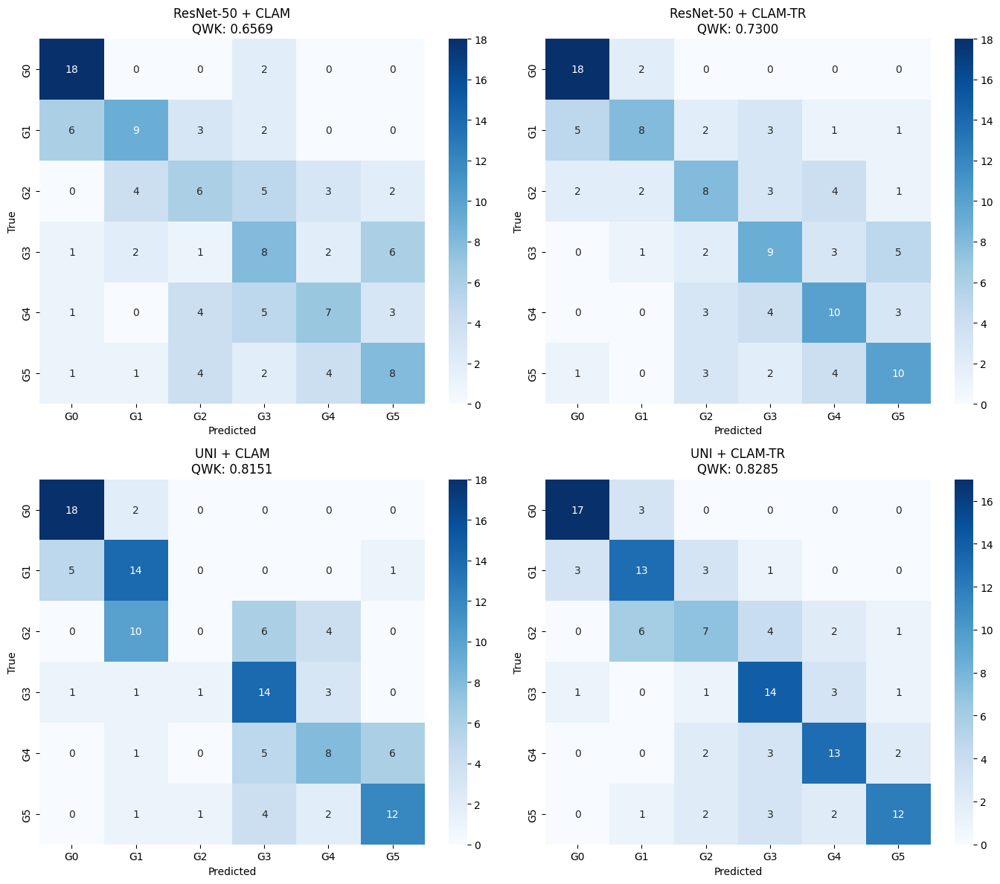

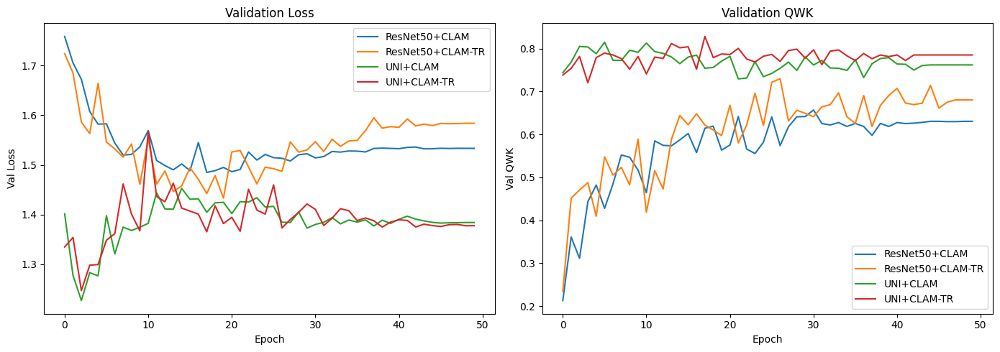

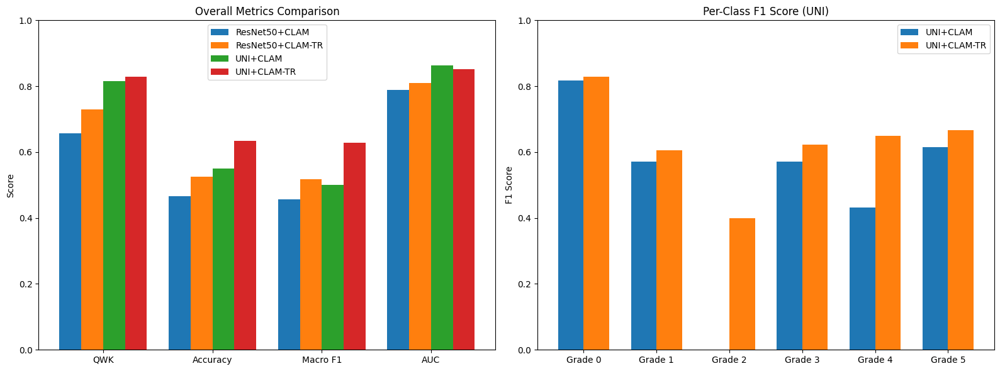

In [ ]:
plot_confusion_matrices(results)
plot_training_curves(results)
plot_results_comparison(results)

---
## Section 12.5: Advanced Visualizations (Attention Analysis)

These visualizations prove that CLAM-TR focuses on actual tumor regions:
1. **Attention vs Ground Truth**: Compare attention heatmaps with pathologist annotations
2. **Top-K Patches Grid**: Display the most attended patches
3. **Spatial Retention Graph**: Visualize spatial connections between Top-K patches

In [ ]:
# ============================================================================
# VISUALIZATION 1: Attention vs Ground Truth
# ============================================================================

def visualize_attention_vs_groundtruth(model, features, coords, slide_id, model_type='clam'):
    """
    Compare model attention with ground truth tumor mask.
    """
    # Paths
    mask_path = os.path.join(CONFIG['ground_truth_masks'], f'{slide_id}_mask.tiff')
    slide_path = os.path.join(CONFIG['subset_folder'], f'{slide_id}.tiff')

    # Target size for all images (fixed size, not aspect-ratio dependent)
    TARGET_SIZE = (1024, 1024)

    # Check if files exist
    if not os.path.exists(mask_path):
        print(f"  Warning: Mask not found: {mask_path}")
        return {'iou': 0.0, 'dice': 0.0}
    if not os.path.exists(slide_path):
        print(f"  Warning: Slide not found: {slide_path}")
        return {'iou': 0.0, 'dice': 0.0}

    # Get attention weights from model
    model.eval()
    with torch.no_grad():
        features_gpu = features.to(DEVICE)
        coords_gpu = coords.to(DEVICE)

        if model_type == 'clam':
            logits, attention = model(features_gpu, return_attention=True)
        else:
            logits, attention, topk_indices = model(features_gpu, coords_gpu, return_attention=True)

    attention = attention.cpu().numpy()
    coords_np = coords.cpu().numpy() if torch.is_tensor(coords) else coords

    try:
        # Load ground truth mask and RESIZE to fixed size (not thumbnail which keeps aspect ratio)
        mask_slide = openslide.OpenSlide(mask_path)
        # Get thumbnail then resize to exact target size
        mask_thumb = mask_slide.get_thumbnail((2048, 2048))  # Get larger first
        mask_thumb_resized = mask_thumb.resize(TARGET_SIZE, Image.Resampling.NEAREST)  # Resize to exact size
        mask_thumbnail = np.array(mask_thumb_resized)
        mask_slide.close()

        # Convert mask to binary (tumor vs non-tumor)
        # PANDA mask values: 0=background, 1=stroma, 2=benign, 3=Gleason 3, 4=Gleason 4, 5=Gleason 5
        if len(mask_thumbnail.shape) == 3:
            tumor_mask = (mask_thumbnail[:, :, 0] >= 3).astype(float)
        else:
            tumor_mask = (mask_thumbnail >= 3).astype(float)

        # Load original slide thumbnail and RESIZE to fixed size
        slide = openslide.OpenSlide(slide_path)
        slide_thumb = slide.get_thumbnail((2048, 2048))  # Get larger first
        slide_thumbnail = slide_thumb.resize(TARGET_SIZE, Image.Resampling.LANCZOS)  # Resize to exact size
        slide_dims = slide.level_dimensions[0]
        slide.close()

    except Exception as e:
        print(f"  Error loading slide/mask: {e}")
        import traceback
        traceback.print_exc()
        return {'iou': 0.0, 'dice': 0.0}

    # Scale coordinates to target size
    scale_x = TARGET_SIZE[0] / slide_dims[0]
    scale_y = TARGET_SIZE[1] / slide_dims[1]
    scaled_coords = coords_np.copy()
    scaled_coords[:, 0] = coords_np[:, 0] * scale_x
    scaled_coords[:, 1] = coords_np[:, 1] * scale_y

    # Create attention heatmap (same size as target)
    attention_map = np.zeros(TARGET_SIZE)
    patch_size_scaled = max(1, int(CONFIG['patch_size'] * scale_x))

    for i, (x, y) in enumerate(scaled_coords):
        x, y = int(x), int(y)
        x_end = min(x + patch_size_scaled, TARGET_SIZE[0])
        y_end = min(y + patch_size_scaled, TARGET_SIZE[1])
        if 0 <= x < TARGET_SIZE[0] and 0 <= y < TARGET_SIZE[1]:
            attention_map[y:y_end, x:x_end] = attention[i]

    # Normalize attention map
    if attention_map.max() > attention_map.min():
        attention_map = (attention_map - attention_map.min()) / (attention_map.max() - attention_map.min())

    # Binarize attention (top 20% = high attention)
    nonzero_attention = attention_map[attention_map > 0]
    if len(nonzero_attention) > 0:
        threshold = np.percentile(nonzero_attention, 80)
        attention_binary = (attention_map >= threshold).astype(float)
    else:
        attention_binary = np.zeros_like(attention_map)

    # Ensure tumor_mask matches attention_binary shape
    if tumor_mask.shape != attention_binary.shape:
        print(f"  Warning: Shape mismatch - tumor_mask {tumor_mask.shape}, attention {attention_binary.shape}")
        print(f"  Resizing tumor_mask to match...")
        from PIL import Image as PILImage
        tumor_mask_pil = PILImage.fromarray((tumor_mask * 255).astype(np.uint8))
        tumor_mask_resized = tumor_mask_pil.resize((attention_binary.shape[1], attention_binary.shape[0]), PILImage.Resampling.NEAREST)
        tumor_mask = np.array(tumor_mask_resized).astype(float) / 255.0

    # Calculate IoU
    intersection = np.logical_and(attention_binary > 0, tumor_mask > 0).sum()
    union = np.logical_or(attention_binary > 0, tumor_mask > 0).sum()
    iou = float(intersection) / float(union + 1e-6)

    # Calculate Dice coefficient
    dice = 2.0 * float(intersection) / (float(attention_binary.sum()) + float(tumor_mask.sum()) + 1e-6)

    # Plot
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    # Row 1: Original, Ground Truth, Attention
    axes[0, 0].imshow(slide_thumbnail)
    axes[0, 0].set_title('Original Slide', fontsize=14)
    axes[0, 0].axis('off')

    axes[0, 1].imshow(tumor_mask, cmap='Reds')
    axes[0, 1].set_title('Ground Truth Tumor Mask', fontsize=14)
    axes[0, 1].axis('off')

    im = axes[0, 2].imshow(attention_map, cmap='hot')
    axes[0, 2].set_title(f'{model_type.upper()} Attention Map', fontsize=14)
    axes[0, 2].axis('off')
    plt.colorbar(im, ax=axes[0, 2], fraction=0.046)

    # Row 2: Overlay, Binary Comparison, Metrics
    axes[1, 0].imshow(slide_thumbnail)
    axes[1, 0].imshow(attention_map, cmap='hot', alpha=0.5)
    axes[1, 0].set_title('Attention Overlay', fontsize=14)
    axes[1, 0].axis('off')

    # Binary comparison (Red=tumor, Blue=attention, Purple=overlap)
    comparison = np.zeros((TARGET_SIZE[0], TARGET_SIZE[1], 3))
    comparison[:, :, 0] = tumor_mask  # Red = ground truth
    comparison[:, :, 2] = attention_binary  # Blue = attention
    axes[1, 1].imshow(comparison)
    axes[1, 1].set_title('Overlap (Red=GT, Blue=Attn, Purple=Both)', fontsize=14)
    axes[1, 1].axis('off')

    # Metrics text
    axes[1, 2].text(0.5, 0.6, f'IoU: {iou:.4f}', fontsize=24, ha='center', va='center',
                    transform=axes[1, 2].transAxes, fontweight='bold')
    axes[1, 2].text(0.5, 0.4, f'Dice: {dice:.4f}', fontsize=24, ha='center', va='center',
                    transform=axes[1, 2].transAxes, fontweight='bold')
    axes[1, 2].set_title(f'Metrics ({model_type.upper()})', fontsize=14)
    axes[1, 2].axis('off')

    plt.suptitle(f'Attention vs Ground Truth - Slide: {slide_id}', fontsize=16, fontweight='bold')
    plt.tight_layout()

    save_path = os.path.join(CONFIG['results_dir'], 'visualizations',
                             f'attention_vs_gt_{slide_id}_{model_type}.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

    return {'iou': iou, 'dice': dice}


def compare_clam_vs_clamtr_attention(slide_id, clam_model, clamtr_model, features, coords):
    """
    Side-by-side comparison of CLAM vs CLAM-TR attention alignment with ground truth.
    """
    print(f"\n{'='*60}")
    print(f"Comparing Attention vs Ground Truth for: {slide_id}")
    print(f"{'='*60}")

    print("\nCLAM Attention:")
    clam_metrics = visualize_attention_vs_groundtruth(clam_model, features, coords, slide_id, 'clam')

    print("\nCLAM-TR Attention:")
    clamtr_metrics = visualize_attention_vs_groundtruth(clamtr_model, features, coords, slide_id, 'clam_tr')

    # Summary comparison
    print(f"\n{'='*60}")
    print(f"SUMMARY - Slide: {slide_id}")
    print(f"{'='*60}")
    print(f"CLAM    - IoU: {clam_metrics['iou']:.4f}, Dice: {clam_metrics['dice']:.4f}")
    print(f"CLAM-TR - IoU: {clamtr_metrics['iou']:.4f}, Dice: {clamtr_metrics['dice']:.4f}")

    iou_improvement = (clamtr_metrics['iou'] - clam_metrics['iou']) * 100
    dice_improvement = (clamtr_metrics['dice'] - clam_metrics['dice']) * 100
    print(f"Improvement - IoU: {iou_improvement:+.2f}%, Dice: {dice_improvement:+.2f}%")

    return clam_metrics, clamtr_metrics

print("Visualization 1: Attention vs Ground Truth - DEFINED")

Visualization 1: Attention vs Ground Truth - DEFINED


In [ ]:
# ============================================================================
# VISUALIZATION 2: Top-K Patches Grid
# ============================================================================

def visualize_topk_patches(model, features, coords, slide_id, top_n=10):
    """
    Display the top-N most attended patches from CLAM-TR.

    Args:
        model: Trained CLAM-TR model
        features: Patch features tensor
        coords: Patch coordinates tensor
        slide_id: Slide identifier
        top_n: Number of top patches to display (default 10 for 2x5 grid)

    Returns:
        dict with top-k patch information
    """
    try:
        model.eval()

        with torch.no_grad():
            features_gpu = features.to(DEVICE)
            coords_gpu = coords.to(DEVICE)
            logits, attention, topk_indices = model(features_gpu, coords_gpu, return_attention=True)

        attention = attention.cpu().numpy()
        coords_np = coords.cpu().numpy() if torch.is_tensor(coords) else coords
        topk_indices = topk_indices.cpu().numpy()

        # Sort topk_indices by attention score (highest first)
        topk_attention_scores = attention[topk_indices]
        sorted_order = np.argsort(topk_attention_scores)[::-1]
        sorted_topk_indices = topk_indices[sorted_order]

        # Get top-N indices
        top_n_indices = sorted_topk_indices[:top_n]
        top_n_attention = attention[top_n_indices]
        top_n_coords = coords_np[top_n_indices]

        # Load patches from saved patch folder
        patches_dir = os.path.join(CONFIG['preprocessing_dir'], 'patches', slide_id)

        # Create figure (2 rows x 5 columns)
        fig, axes = plt.subplots(2, 5, figsize=(20, 8))
        axes = axes.flatten()

        patch_info = []

        for i, (idx, att_score, coord) in enumerate(zip(top_n_indices, top_n_attention, top_n_coords)):
            if i >= top_n:
                break

            # Load patch image
            patch_path = os.path.join(patches_dir, f'patch_{int(coord[0])}_{int(coord[1])}.png')

            if os.path.exists(patch_path):
                patch_img = Image.open(patch_path)
                axes[i].imshow(patch_img)

                # Add red border for emphasis
                for spine in axes[i].spines.values():
                    spine.set_edgecolor('red')
                    spine.set_linewidth(3)
            else:
                # If patch not found, show placeholder
                axes[i].text(0.5, 0.5, 'Patch\nNot Found',
                            ha='center', va='center', fontsize=12,
                            transform=axes[i].transAxes)
                axes[i].set_facecolor('lightgray')

            axes[i].set_title(f'Rank #{i+1}\nAttn: {att_score:.4f}\n({int(coord[0])}, {int(coord[1])})',
                             fontsize=10, fontweight='bold')
            axes[i].axis('off')

            patch_info.append({
                'rank': i + 1,
                'attention': float(att_score),
                'x': int(coord[0]),
                'y': int(coord[1])
            })

        plt.suptitle(f'Top-{top_n} Most Attended Patches (CLAM-TR) - Slide: {slide_id}',
                     fontsize=16, fontweight='bold')
        plt.tight_layout()

        save_path = os.path.join(CONFIG['results_dir'], 'visualizations',
                                 f'topk_patches_{slide_id}.png')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

        # Print patch info
        print(f"\nTop-{top_n} Patches for {slide_id}:")
        print("-" * 40)
        for info in patch_info:
            print(f"  Rank {info['rank']}: Attention={info['attention']:.4f}, Coord=({info['x']}, {info['y']})")

        return {'slide_id': slide_id, 'patches': patch_info}

    except Exception as e:
        print(f"  Error in visualize_topk_patches: {e}")
        plt.close('all')
        return {'slide_id': slide_id, 'patches': [], 'error': str(e)}


def visualize_topk_on_slide(model, features, coords, slide_id):
    """
    Overlay Top-K patch locations on the slide thumbnail.
    Shows where CLAM-TR focuses its attention.
    """
    try:
        model.eval()

        with torch.no_grad():
            features_gpu = features.to(DEVICE)
            coords_gpu = coords.to(DEVICE)
            logits, attention, topk_indices = model(features_gpu, coords_gpu, return_attention=True)

        attention = attention.cpu().numpy()
        coords_np = coords.cpu().numpy() if torch.is_tensor(coords) else coords
        topk_indices = topk_indices.cpu().numpy()

        # Load slide thumbnail
        slide_path = os.path.join(CONFIG['subset_folder'], f'{slide_id}.tiff')
        if not os.path.exists(slide_path):
            print(f"  Slide not found: {slide_id}")
            return

        slide = openslide.OpenSlide(slide_path)
        thumbnail = slide.get_thumbnail((1024, 1024))
        slide_dims = slide.level_dimensions[0]
        slide.close()

        # Scale coordinates
        scale_x = 1024 / slide_dims[0]
        scale_y = 1024 / slide_dims[1]

        # Get Top-K coordinates and attention
        topk_coords = coords_np[topk_indices]
        topk_attention = attention[topk_indices]

        scaled_topk_coords = topk_coords.copy()
        scaled_topk_coords[:, 0] *= scale_x
        scaled_topk_coords[:, 1] *= scale_y

        # Normalize attention for color mapping
        att_range = topk_attention.max() - topk_attention.min()
        if att_range > 0:
            norm_attention = (topk_attention - topk_attention.min()) / att_range
        else:
            norm_attention = np.ones_like(topk_attention)

        # Create figure
        fig, axes = plt.subplots(1, 2, figsize=(16, 8))

        # Left: Original slide
        axes[0].imshow(thumbnail)
        axes[0].set_title('Original Slide', fontsize=14)
        axes[0].axis('off')

        # Right: Slide with Top-K patches highlighted
        axes[1].imshow(thumbnail)
        scatter = axes[1].scatter(scaled_topk_coords[:, 0], scaled_topk_coords[:, 1],
                                  c=norm_attention, cmap='hot', s=50, alpha=0.8,
                                  edgecolors='white', linewidths=0.5)
        plt.colorbar(scatter, ax=axes[1], label='Attention Score', fraction=0.046)
        axes[1].set_title(f'Top-K Patch Locations (K={len(topk_indices)})', fontsize=14)
        axes[1].axis('off')

        plt.suptitle(f'CLAM-TR Top-K Focus Areas - Slide: {slide_id}', fontsize=16, fontweight='bold')
        plt.tight_layout()

        save_path = os.path.join(CONFIG['results_dir'], 'visualizations',
                                 f'topk_locations_{slide_id}.png')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    except Exception as e:
        print(f"  Error in visualize_topk_on_slide: {e}")
        plt.close('all')

print("Visualization 2: Top-K Patches Grid - DEFINED")

Visualization 2: Top-K Patches Grid - DEFINED


In [ ]:
# ============================================================================
# VISUALIZATION 3: Spatial Retention Graph
# ============================================================================

def visualize_spatial_retention(model, features, coords, slide_id, gamma=0.95, top_connections=50):
    """
    Visualize spatial retention connections between Top-K patches.
    Shows patches as nodes and retention weights as edges.

    Args:
        model: Trained CLAM-TR model
        features: Patch features tensor
        coords: Patch coordinates tensor
        slide_id: Slide identifier
        gamma: Decay factor for visualization (default 0.95)
        top_connections: Number of strongest connections to show

    Returns:
        dict with spatial retention statistics
    """
    try:
        model.eval()

        with torch.no_grad():
            features_gpu = features.to(DEVICE)
            coords_gpu = coords.to(DEVICE)
            logits, attention, topk_indices = model(features_gpu, coords_gpu, return_attention=True)

        coords_np = coords.cpu().numpy() if torch.is_tensor(coords) else coords
        topk_indices = topk_indices.cpu().numpy()
        attention = attention.cpu().numpy()

        # Get Top-K coordinates
        topk_coords = coords_np[topk_indices]
        topk_attention = attention[topk_indices]
        K = len(topk_coords)

        # Compute pairwise distance matrix
        diff = topk_coords[:, np.newaxis, :] - topk_coords[np.newaxis, :, :]
        distances = np.linalg.norm(diff, axis=-1)

        # Normalize distances to [0, 1]
        max_dist = distances.max() + 1e-6
        normalized_dist = distances / max_dist

        # Compute retention weights: gamma^(normalized_distance)
        retention_weights = gamma ** normalized_dist

        # Load slide thumbnail
        slide_path = os.path.join(CONFIG['subset_folder'], f'{slide_id}.tiff')
        if not os.path.exists(slide_path):
            print(f"  Slide not found: {slide_id}")
            return {}

        slide = openslide.OpenSlide(slide_path)
        thumbnail = slide.get_thumbnail((1024, 1024))
        slide_dims = slide.level_dimensions[0]
        slide.close()

        # Scale coordinates to thumbnail
        scale_x = 1024 / slide_dims[0]
        scale_y = 1024 / slide_dims[1]
        scaled_coords = topk_coords.copy()
        scaled_coords[:, 0] *= scale_x
        scaled_coords[:, 1] *= scale_y

        # Create figure with 3 subplots
        fig, axes = plt.subplots(1, 3, figsize=(20, 7))

        # -------------------------------------------------------------------------
        # Panel 1: Top-K patches on slide (nodes only)
        # -------------------------------------------------------------------------
        axes[0].imshow(thumbnail)

        # Color nodes by attention score
        att_range = topk_attention.max() - topk_attention.min() + 1e-6
        norm_attention = (topk_attention - topk_attention.min()) / att_range
        scatter = axes[0].scatter(scaled_coords[:, 0], scaled_coords[:, 1],
                                  c=norm_attention, cmap='hot', s=60, alpha=0.9,
                                  edgecolors='white', linewidths=1)
        plt.colorbar(scatter, ax=axes[0], label='Attention', fraction=0.046)
        axes[0].set_title(f'Top-K Patches (K={K})', fontsize=14)
        axes[0].axis('off')

        # -------------------------------------------------------------------------
        # Panel 2: Spatial retention connections (graph view)
        # -------------------------------------------------------------------------
        axes[1].imshow(thumbnail, alpha=0.4)

        # Get upper triangular indices (avoid duplicate edges)
        triu_indices = np.triu_indices(K, k=1)
        edge_weights = retention_weights[triu_indices]

        # Sort edges by weight and take top connections
        sorted_edge_idx = np.argsort(edge_weights)[::-1][:top_connections]

        # Draw edges (connections between patches)
        for idx in sorted_edge_idx:
            i, j = triu_indices[0][idx], triu_indices[1][idx]
            weight = float(edge_weights[idx])

            # Line properties based on weight
            linewidth = weight * 4  # Thicker = stronger connection
            alpha = 0.3 + weight * 0.6  # More opaque = stronger

            # Draw line
            axes[1].plot([scaled_coords[i, 0], scaled_coords[j, 0]],
                         [scaled_coords[i, 1], scaled_coords[j, 1]],
                         color='blue', linewidth=linewidth, alpha=alpha)

        # Draw nodes on top
        axes[1].scatter(scaled_coords[:, 0], scaled_coords[:, 1],
                        c='red', s=80, alpha=0.9,
                        edgecolors='white', linewidths=1.5, zorder=5)

        axes[1].set_title(f'Spatial Retention Graph\n(Top {top_connections} connections, gamma={gamma})', fontsize=14)
        axes[1].axis('off')

        # -------------------------------------------------------------------------
        # Panel 3: Retention weight heatmap (distance decay visualization)
        # -------------------------------------------------------------------------
        # Show retention matrix as heatmap
        im = axes[2].imshow(retention_weights, cmap='viridis', aspect='auto')
        plt.colorbar(im, ax=axes[2], label='Retention Weight', fraction=0.046)
        axes[2].set_title(f'Retention Weight Matrix\n(gamma^distance, gamma={gamma})', fontsize=14)
        axes[2].set_xlabel('Patch Index')
        axes[2].set_ylabel('Patch Index')

        plt.suptitle(f'Spatial Retention Visualization - Slide: {slide_id}', fontsize=16, fontweight='bold')
        plt.tight_layout()

        save_path = os.path.join(CONFIG['results_dir'], 'visualizations',
                                 f'spatial_retention_{slide_id}.png')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

        # Compute statistics
        stats = {
            'slide_id': slide_id,
            'num_patches': K,
            'mean_retention': float(retention_weights.mean()),
            'max_distance': float(max_dist),
            'mean_distance': float(distances.mean()),
            'gamma': gamma
        }

        print(f"\nSpatial Retention Statistics for {slide_id}:")
        print(f"  - Number of Top-K patches: {K}")
        print(f"  - Mean retention weight: {stats['mean_retention']:.4f}")
        print(f"  - Max pairwise distance: {stats['max_distance']:.1f} pixels")
        print(f"  - Mean pairwise distance: {stats['mean_distance']:.1f} pixels")

        return stats

    except Exception as e:
        print(f"  Error in visualize_spatial_retention: {e}")
        plt.close('all')
        return {'slide_id': slide_id, 'error': str(e)}


def visualize_multi_gamma_retention(model, features, coords, slide_id):
    """
    Compare retention patterns across different gamma values.
    Shows how different gamma values affect spatial connectivity.
    """
    try:
        gamma_values = CONFIG['gamma_values']

        model.eval()
        with torch.no_grad():
            features_gpu = features.to(DEVICE)
            coords_gpu = coords.to(DEVICE)
            logits, attention, topk_indices = model(features_gpu, coords_gpu, return_attention=True)

        coords_np = coords.cpu().numpy() if torch.is_tensor(coords) else coords
        topk_indices = topk_indices.cpu().numpy()

        # Get Top-K coordinates
        topk_coords = coords_np[topk_indices]
        K = len(topk_coords)

        # Compute distance matrix
        diff = topk_coords[:, np.newaxis, :] - topk_coords[np.newaxis, :, :]
        distances = np.linalg.norm(diff, axis=-1)
        max_dist = distances.max() + 1e-6
        normalized_dist = distances / max_dist

        # Load slide thumbnail
        slide_path = os.path.join(CONFIG['subset_folder'], f'{slide_id}.tiff')
        if not os.path.exists(slide_path):
            print(f"  Slide not found: {slide_id}")
            return

        slide = openslide.OpenSlide(slide_path)
        thumbnail = slide.get_thumbnail((512, 512))  # Smaller for grid
        slide_dims = slide.level_dimensions[0]
        slide.close()

        # Scale coordinates
        scale_x = 512 / slide_dims[0]
        scale_y = 512 / slide_dims[1]
        scaled_coords = topk_coords.copy()
        scaled_coords[:, 0] *= scale_x
        scaled_coords[:, 1] *= scale_y

        # Create grid: 2 rows x 4 columns for 8 gamma values
        fig, axes = plt.subplots(2, 4, figsize=(20, 10))
        axes = axes.flatten()

        for idx, gamma in enumerate(gamma_values[:8]):
            ax = axes[idx]

            # Compute retention weights for this gamma
            retention_weights = gamma ** normalized_dist

            # Get top 30 connections
            triu_indices = np.triu_indices(K, k=1)
            edge_weights = retention_weights[triu_indices]
            sorted_edge_idx = np.argsort(edge_weights)[::-1][:30]

            # Draw
            ax.imshow(thumbnail, alpha=0.4)

            for edge_idx in sorted_edge_idx:
                i, j = triu_indices[0][edge_idx], triu_indices[1][edge_idx]
                weight = float(edge_weights[edge_idx])
                ax.plot([scaled_coords[i, 0], scaled_coords[j, 0]],
                        [scaled_coords[i, 1], scaled_coords[j, 1]],
                        color='blue', linewidth=weight * 3, alpha=0.3 + weight * 0.5)

            ax.scatter(scaled_coords[:, 0], scaled_coords[:, 1],
                       c='red', s=30, alpha=0.8, edgecolors='white', linewidths=0.5, zorder=5)

            mean_weight = float(retention_weights.mean())
            ax.set_title(f'gamma = {gamma}\nMean weight: {mean_weight:.3f}', fontsize=11)
            ax.axis('off')

        plt.suptitle(f'Multi-Head Gamma Comparison - Slide: {slide_id}\n(8 heads with different gamma values capture different spatial scales)',
                     fontsize=14, fontweight='bold')
        plt.tight_layout()

        save_path = os.path.join(CONFIG['results_dir'], 'visualizations',
                                 f'multi_gamma_{slide_id}.png')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close()

    except Exception as e:
        print(f"  Error in visualize_multi_gamma_retention: {e}")
        plt.close('all')

print("Visualization 3: Spatial Retention Graph - DEFINED")

Visualization 3: Spatial Retention Graph - DEFINED


In [ ]:
# ============================================================================
# COMPREHENSIVE VISUALIZATION RUNNER
# ============================================================================

def run_advanced_visualizations(num_samples=5):
    """
    Generate all advanced visualizations for sample slides (one per grade).

    Args:
        num_samples: Number of sample slides to visualize (default 5, one per grade 1-5)

    Returns:
        dict with all visualization results and IoU summary
    """
    print("\n" + "="*80)
    print("GENERATING ADVANCED VISUALIZATIONS")
    print("="*80)

    # Load the subset CSV to get slide info
    subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
    df = pd.read_csv(subset_csv)

    # Get one sample slide per grade (grades 1-5, skip grade 0 as it's benign)
    sample_slides = []
    for grade in range(1, 6):
        grade_slides = df[df['isup_grade'] == grade]['image_id'].tolist()
        if grade_slides:
            sample_slides.append((grade_slides[0], grade))

    sample_slides = sample_slides[:num_samples]
    print(f"Selected {len(sample_slides)} sample slides (one per grade)")

    # Load best UNI models (CLAM and CLAM-TR)
    print("\nLoading trained models...")

    clam_model = CLAM(CONFIG['feature_dim'], CONFIG['hidden_dim'], CONFIG['n_classes'], CONFIG['dropout'])
    clam_model_path = os.path.join(CONFIG['results_dir'], 'models', 'exp3_uni_clam_best.pt')
    if os.path.exists(clam_model_path):
        clam_model.load_state_dict(torch.load(clam_model_path, map_location=DEVICE))
        print("  - UNI+CLAM model loaded")
    else:
        print("  - WARNING: CLAM model not found, using untrained model")
    clam_model.to(DEVICE)
    clam_model.eval()

    clamtr_model = CLAM_TR(CONFIG['feature_dim'], CONFIG['hidden_dim'], CONFIG['n_classes'],
                           CONFIG['dropout'], CONFIG['K'], CONFIG['num_heads'], CONFIG['gamma_values'])
    clamtr_model_path = os.path.join(CONFIG['results_dir'], 'models', 'exp4_uni_clam_tr_best.pt')
    if os.path.exists(clamtr_model_path):
        clamtr_model.load_state_dict(torch.load(clamtr_model_path, map_location=DEVICE))
        print("  - UNI+CLAM-TR model loaded")
    else:
        print("  - WARNING: CLAM-TR model not found, using untrained model")
    clamtr_model.to(DEVICE)
    clamtr_model.eval()

    # Store results
    all_results = {
        'attention_iou': {'clam': [], 'clam_tr': [], 'slides': [], 'grades': []},
        'topk_patches': [],
        'spatial_retention': []
    }

    # Generate visualizations for each sample slide
    for slide_id, grade in sample_slides:
        print(f"\n{'='*60}")
        print(f"Processing slide: {slide_id} (Grade {grade})")
        print(f"{'='*60}")

        # Load features (UNI)
        feature_path = os.path.join(CONFIG['features_dir'], 'uni', f'{slide_id}.pt')
        if not os.path.exists(feature_path):
            print(f"  - Features not found, skipping...")
            continue

        data = torch.load(feature_path, map_location='cpu')
        features = data['features']
        coords = data['coordinates']

        print(f"  - Loaded {features.shape[0]} patches")

        # -----------------------------------------------------------------
        # 1. Attention vs Ground Truth (CLAM vs CLAM-TR comparison)
        # -----------------------------------------------------------------
        print("\n  [1/3] Attention vs Ground Truth...")
        clam_metrics, clamtr_metrics = compare_clam_vs_clamtr_attention(
            slide_id, clam_model, clamtr_model, features, coords)

        all_results['attention_iou']['clam'].append(clam_metrics['iou'])
        all_results['attention_iou']['clam_tr'].append(clamtr_metrics['iou'])
        all_results['attention_iou']['slides'].append(slide_id)
        all_results['attention_iou']['grades'].append(grade)

        # -----------------------------------------------------------------
        # 2. Top-K Patches Grid (CLAM-TR only)
        # -----------------------------------------------------------------
        print("\n  [2/3] Top-K Patches Grid...")
        topk_info = visualize_topk_patches(clamtr_model, features, coords, slide_id)
        visualize_topk_on_slide(clamtr_model, features, coords, slide_id)
        all_results['topk_patches'].append(topk_info)

        # -----------------------------------------------------------------
        # 3. Spatial Retention Graph
        # -----------------------------------------------------------------
        print("\n  [3/3] Spatial Retention Graph...")
        retention_stats = visualize_spatial_retention(clamtr_model, features, coords, slide_id)
        visualize_multi_gamma_retention(clamtr_model, features, coords, slide_id)
        all_results['spatial_retention'].append(retention_stats)

        # Clear GPU memory
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # =========================================================================
    # SUMMARY STATISTICS
    # =========================================================================
    print("\n" + "="*80)
    print("ATTENTION-TUMOR ALIGNMENT SUMMARY (IoU)")
    print("="*80)

    clam_ious = all_results['attention_iou']['clam']
    clamtr_ious = all_results['attention_iou']['clam_tr']

    if len(clam_ious) > 0:
        print(f"\nUNI+CLAM Mean IoU:    {np.mean(clam_ious):.4f} +/- {np.std(clam_ious):.4f}")
        print(f"UNI+CLAM-TR Mean IoU: {np.mean(clamtr_ious):.4f} +/- {np.std(clamtr_ious):.4f}")

        improvement = (np.mean(clamtr_ious) - np.mean(clam_ious)) * 100
        print(f"Improvement:          {improvement:+.2f}%")

        # Per-slide breakdown
        print("\nPer-Slide Breakdown:")
        print("-" * 60)
        for i, (slide_id, grade) in enumerate(zip(all_results['attention_iou']['slides'],
                                                   all_results['attention_iou']['grades'])):
            clam_iou = clam_ious[i]
            clamtr_iou = clamtr_ious[i]
            diff = (clamtr_iou - clam_iou) * 100
            print(f"  Grade {grade} ({slide_id[:8]}...): CLAM={clam_iou:.4f}, CLAM-TR={clamtr_iou:.4f}, Diff={diff:+.2f}%")

        # Save results to CSV
        iou_df = pd.DataFrame({
            'Slide': all_results['attention_iou']['slides'],
            'Grade': all_results['attention_iou']['grades'],
            'CLAM_IoU': clam_ious,
            'CLAMTR_IoU': clamtr_ious,
            'Improvement': [c - cl for c, cl in zip(clamtr_ious, clam_ious)]
        })
        iou_csv_path = os.path.join(CONFIG['results_dir'], 'attention_iou_results.csv')
        iou_df.to_csv(iou_csv_path, index=False)
        print(f"\nResults saved to: {iou_csv_path}")

    print("\n" + "="*80)
    print("ALL ADVANCED VISUALIZATIONS COMPLETE!")
    print("="*80)
    print(f"Visualizations saved to: {os.path.join(CONFIG['results_dir'], 'visualizations')}")

    # Clean up
    del clam_model, clamtr_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return all_results

print("Comprehensive Visualization Runner - DEFINED")

Comprehensive Visualization Runner - DEFINED



GENERATING ADVANCED VISUALIZATIONS
Selected 5 sample slides (one per grade)

Loading trained models...
  - UNI+CLAM model loaded
  - UNI+CLAM-TR model loaded

Processing slide: c95bfd7e7fcb784d245163e8305143cc (Grade 1)
  - Loaded 378 patches

  [1/3] Attention vs Ground Truth...

Comparing Attention vs Ground Truth for: c95bfd7e7fcb784d245163e8305143cc

CLAM Attention:


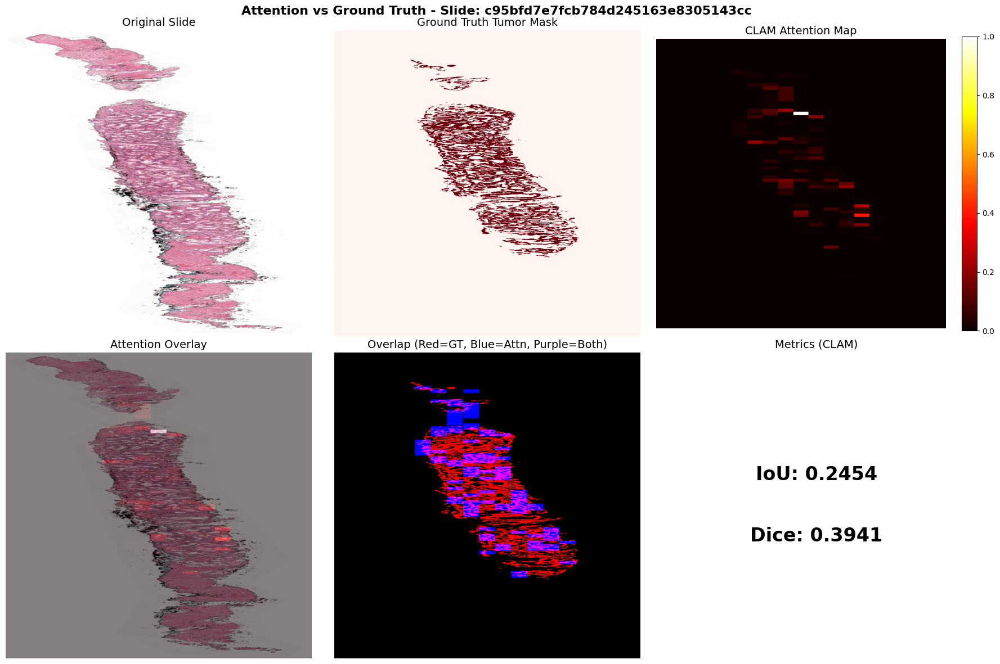


CLAM-TR Attention:


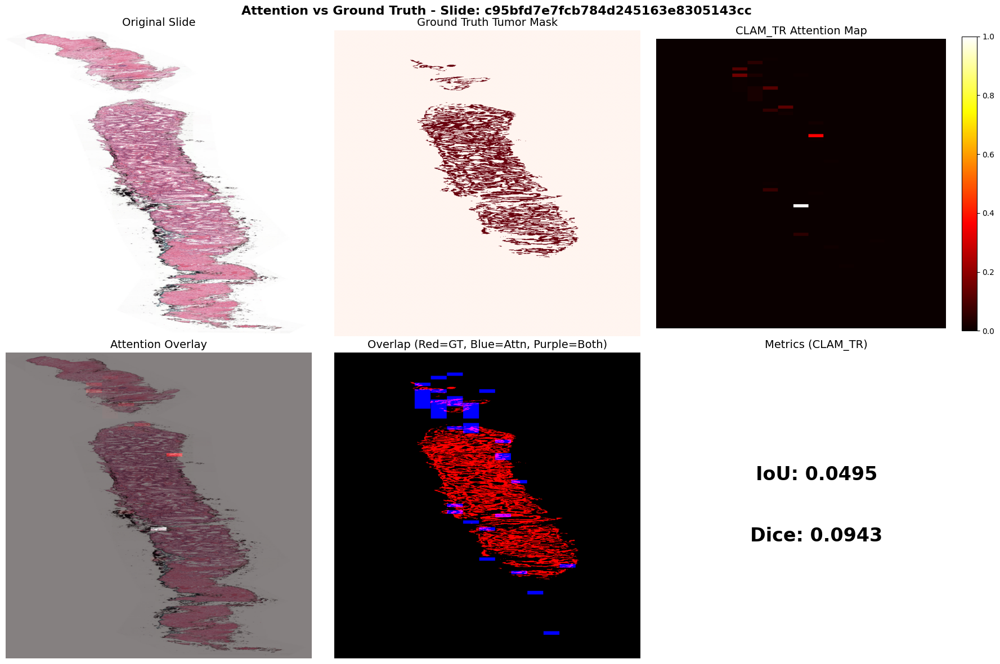


SUMMARY - Slide: c95bfd7e7fcb784d245163e8305143cc
CLAM    - IoU: 0.2454, Dice: 0.3941
CLAM-TR - IoU: 0.0495, Dice: 0.0943
Improvement - IoU: -19.60%, Dice: -29.99%

  [2/3] Top-K Patches Grid...


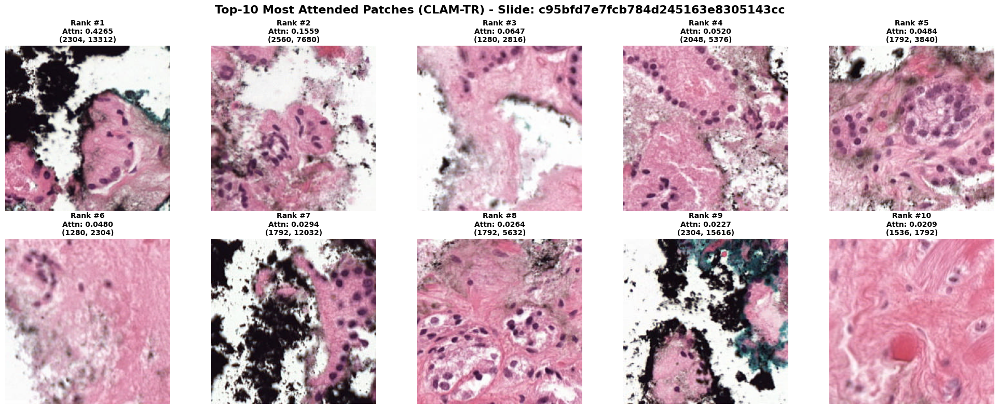


Top-10 Patches for c95bfd7e7fcb784d245163e8305143cc:
----------------------------------------
  Rank 1: Attention=0.4265, Coord=(2304, 13312)
  Rank 2: Attention=0.1559, Coord=(2560, 7680)
  Rank 3: Attention=0.0647, Coord=(1280, 2816)
  Rank 4: Attention=0.0520, Coord=(2048, 5376)
  Rank 5: Attention=0.0484, Coord=(1792, 3840)
  Rank 6: Attention=0.0480, Coord=(1280, 2304)
  Rank 7: Attention=0.0294, Coord=(1792, 12032)
  Rank 8: Attention=0.0264, Coord=(1792, 5632)
  Rank 9: Attention=0.0227, Coord=(2304, 15616)
  Rank 10: Attention=0.0209, Coord=(1536, 1792)


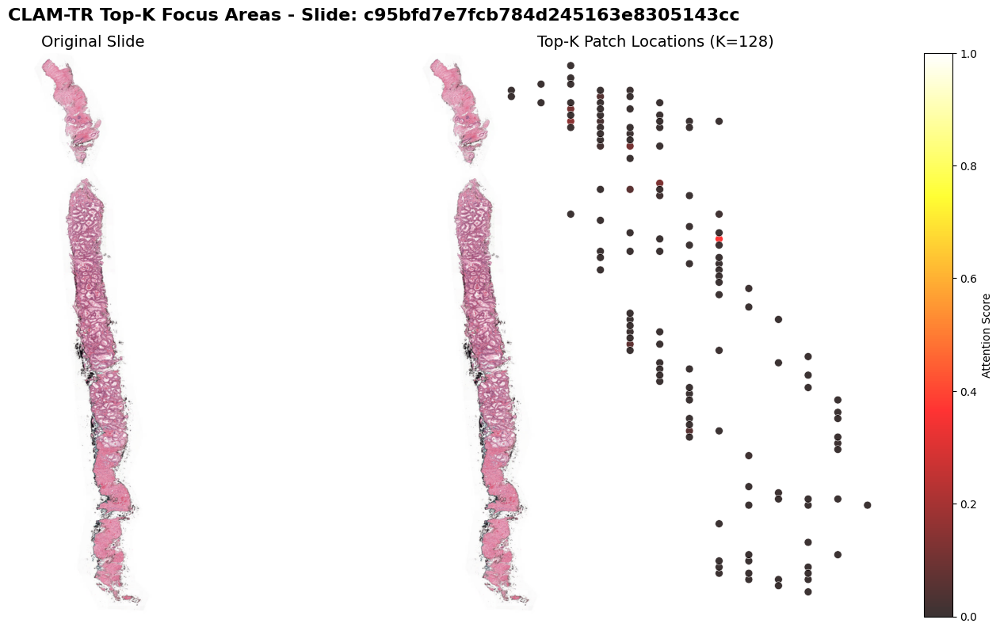


  [3/3] Spatial Retention Graph...


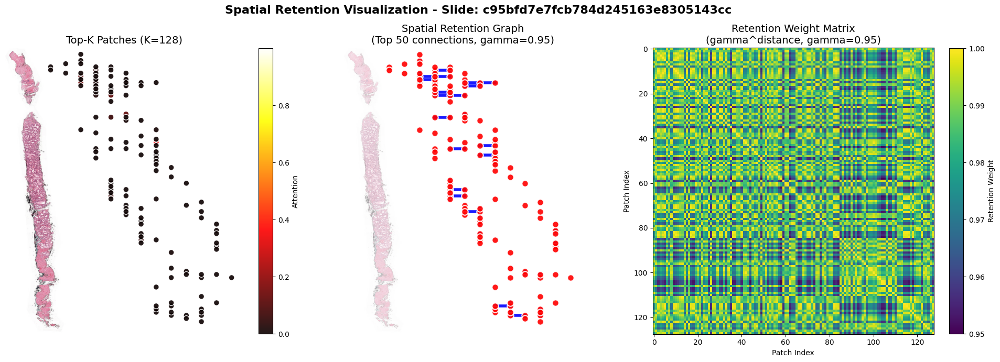


Spatial Retention Statistics for c95bfd7e7fcb784d245163e8305143cc:
  - Number of Top-K patches: 128
  - Mean retention weight: 0.9824
  - Max pairwise distance: 21856.2 pixels
  - Mean pairwise distance: 7602.3 pixels


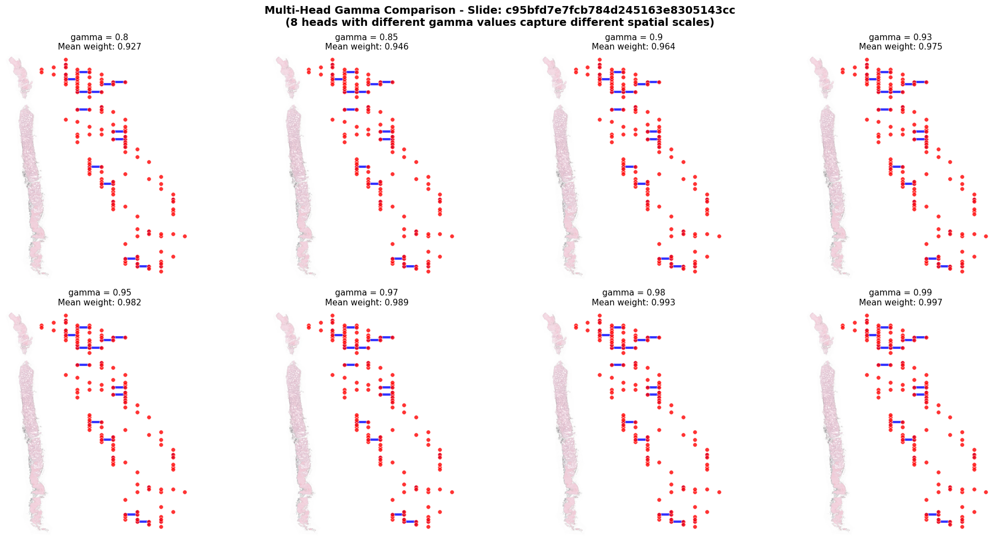


Processing slide: 9cd1f9700bb8591c07051ddd50ccdbe7 (Grade 2)
  - Loaded 307 patches

  [1/3] Attention vs Ground Truth...

Comparing Attention vs Ground Truth for: 9cd1f9700bb8591c07051ddd50ccdbe7

CLAM Attention:


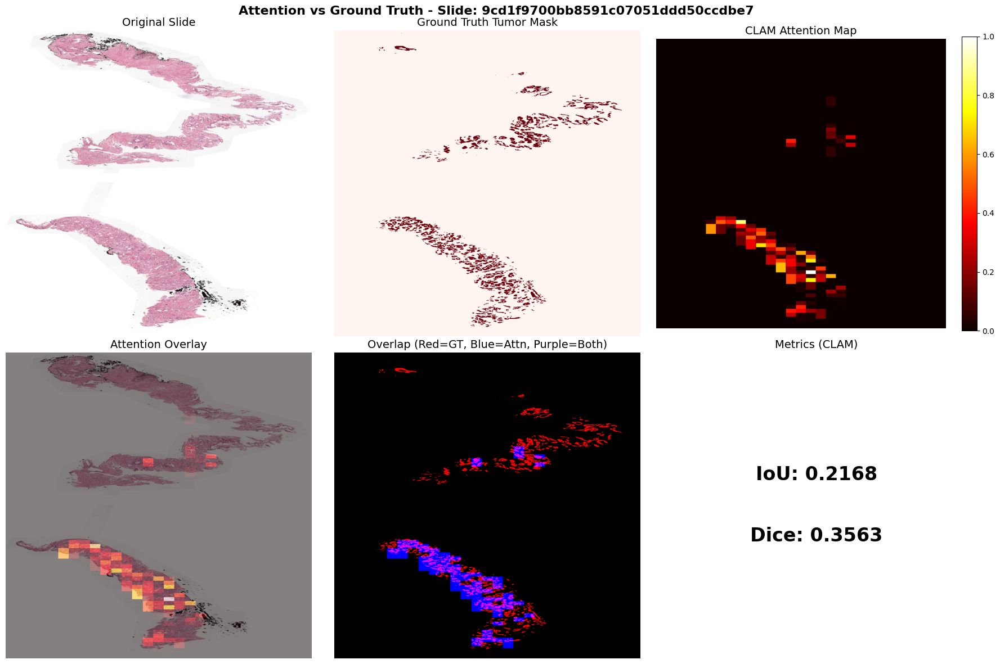


CLAM-TR Attention:


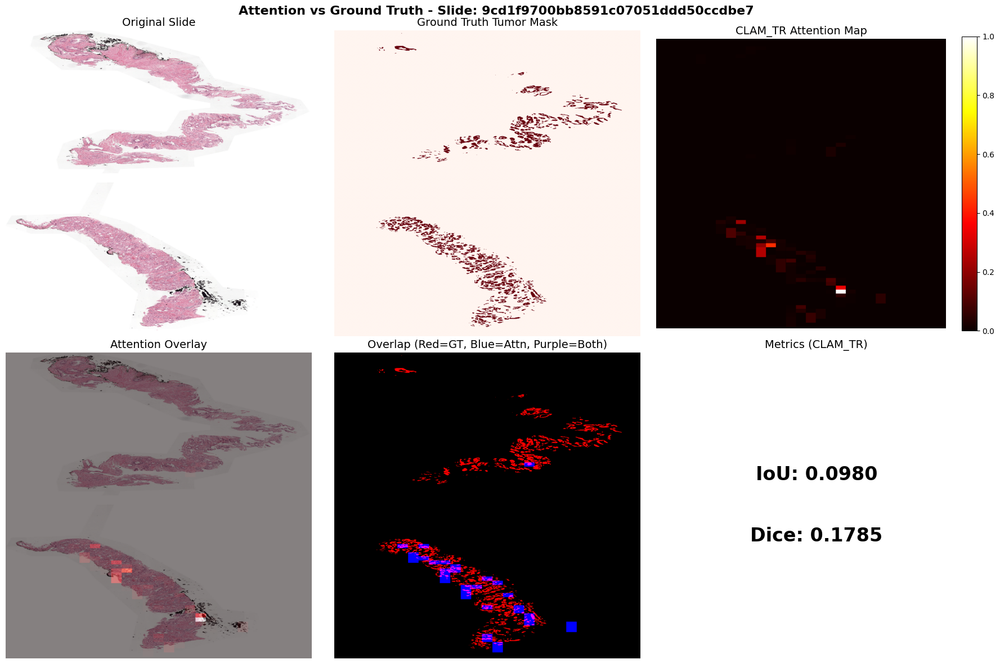


SUMMARY - Slide: 9cd1f9700bb8591c07051ddd50ccdbe7
CLAM    - IoU: 0.2168, Dice: 0.3563
CLAM-TR - IoU: 0.0980, Dice: 0.1785
Improvement - IoU: -11.88%, Dice: -17.78%

  [2/3] Top-K Patches Grid...


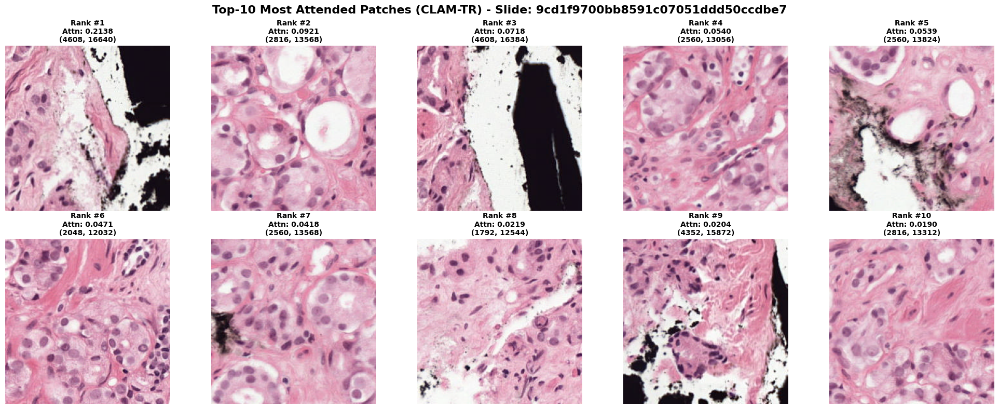


Top-10 Patches for 9cd1f9700bb8591c07051ddd50ccdbe7:
----------------------------------------
  Rank 1: Attention=0.2138, Coord=(4608, 16640)
  Rank 2: Attention=0.0921, Coord=(2816, 13568)
  Rank 3: Attention=0.0718, Coord=(4608, 16384)
  Rank 4: Attention=0.0540, Coord=(2560, 13056)
  Rank 5: Attention=0.0539, Coord=(2560, 13824)
  Rank 6: Attention=0.0471, Coord=(2048, 12032)
  Rank 7: Attention=0.0418, Coord=(2560, 13568)
  Rank 8: Attention=0.0219, Coord=(1792, 12544)
  Rank 9: Attention=0.0204, Coord=(4352, 15872)
  Rank 10: Attention=0.0190, Coord=(2816, 13312)


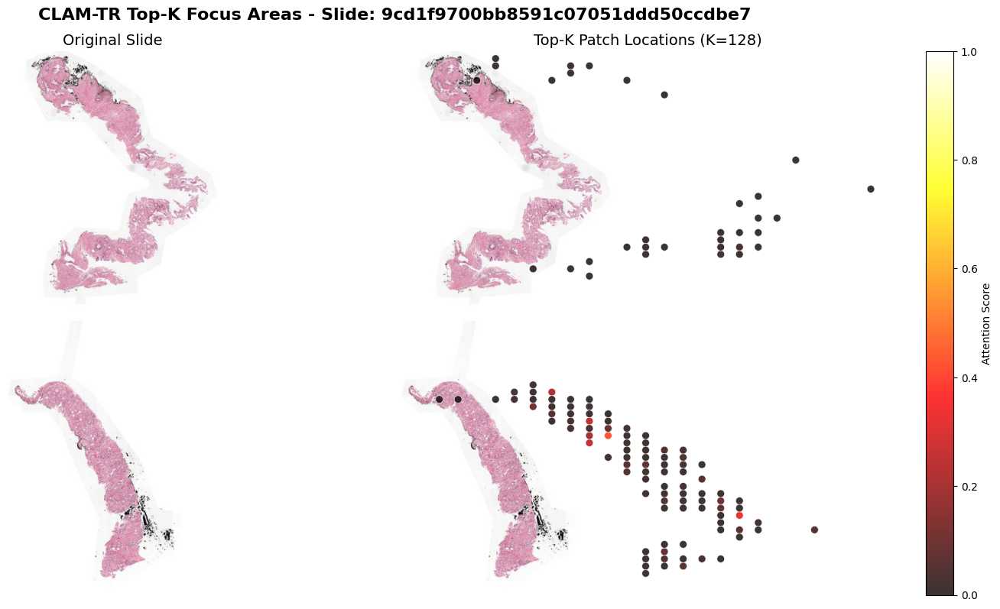


  [3/3] Spatial Retention Graph...


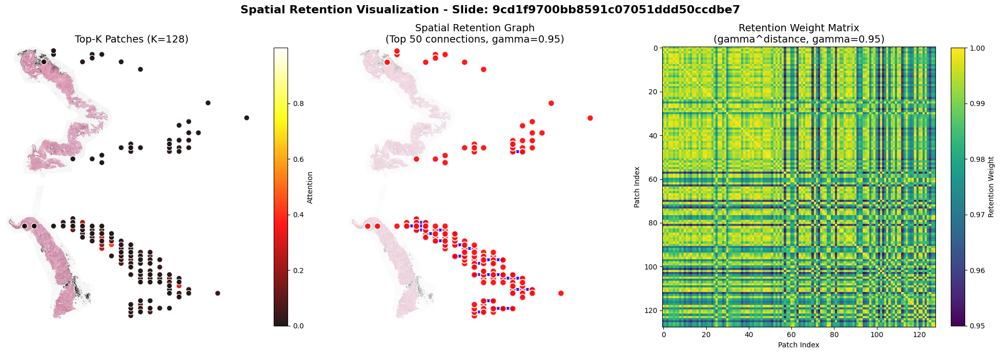


Spatial Retention Statistics for 9cd1f9700bb8591c07051ddd50ccdbe7:
  - Number of Top-K patches: 128
  - Mean retention weight: 0.9849
  - Max pairwise distance: 18291.0 pixels
  - Mean pairwise distance: 5437.2 pixels


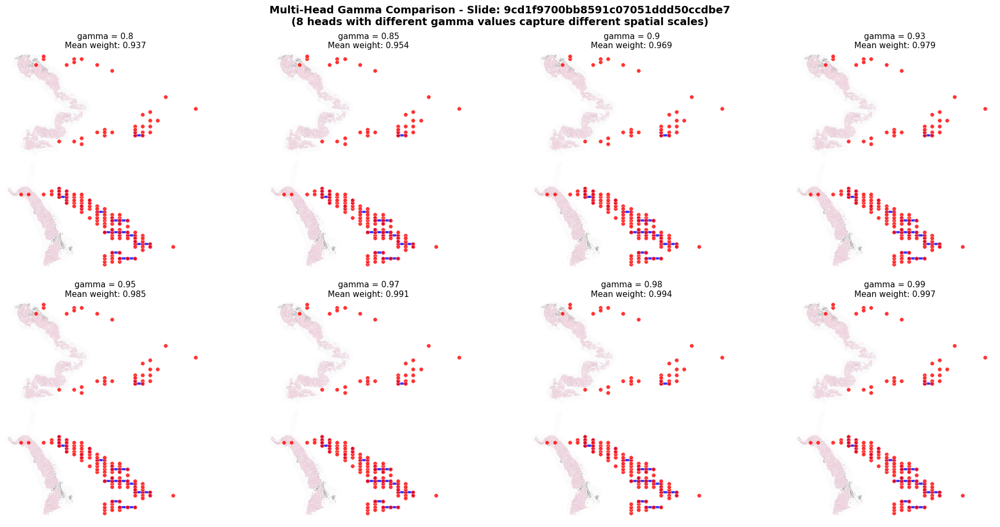


Processing slide: b9008f036f702db353bf6e77470b1b05 (Grade 3)
  - Loaded 115 patches

  [1/3] Attention vs Ground Truth...

Comparing Attention vs Ground Truth for: b9008f036f702db353bf6e77470b1b05

CLAM Attention:


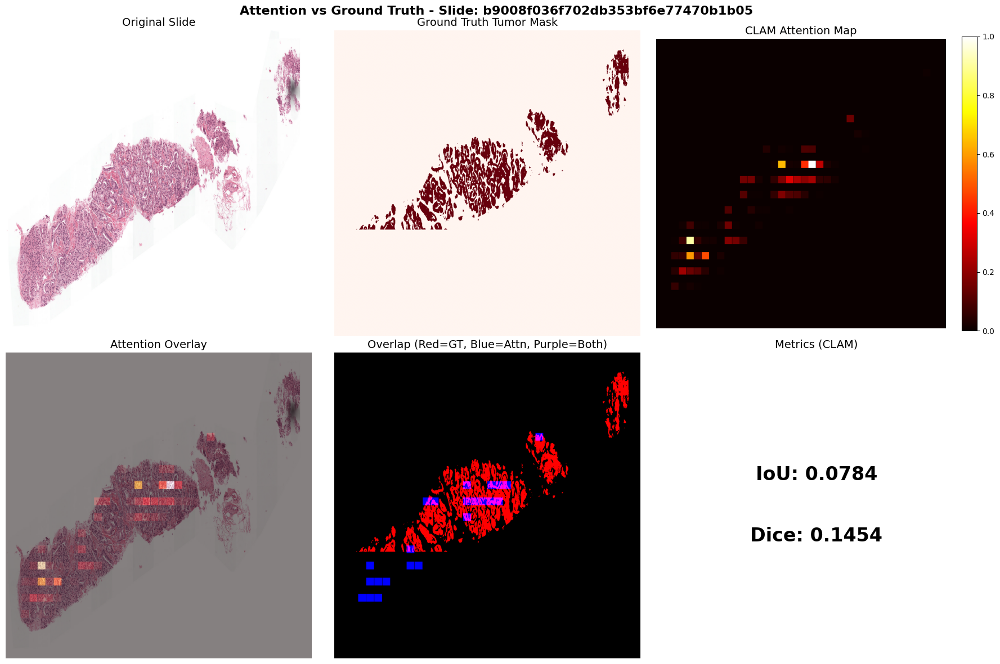


CLAM-TR Attention:


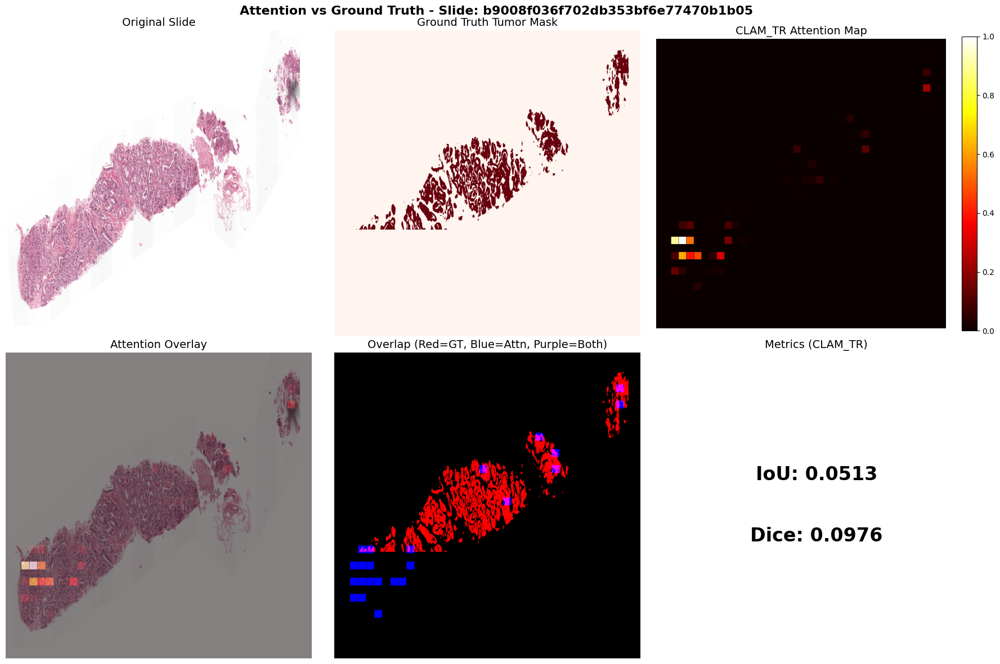


SUMMARY - Slide: b9008f036f702db353bf6e77470b1b05
CLAM    - IoU: 0.0784, Dice: 0.1454
CLAM-TR - IoU: 0.0513, Dice: 0.0976
Improvement - IoU: -2.71%, Dice: -4.78%

  [2/3] Top-K Patches Grid...


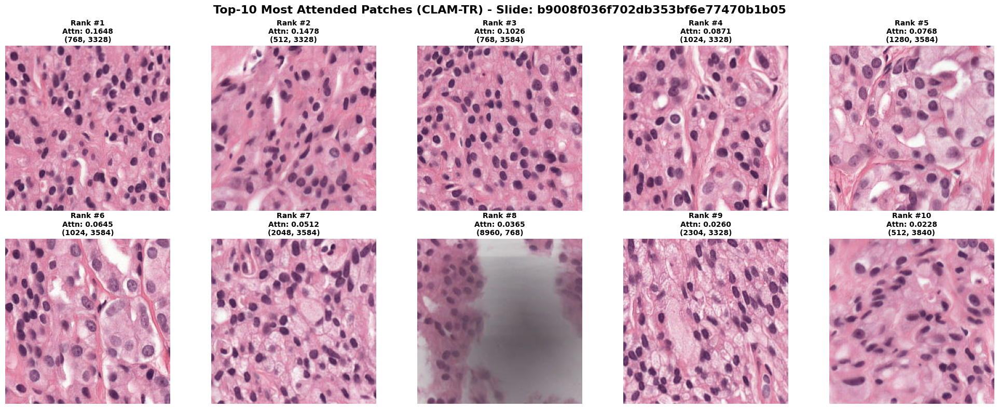


Top-10 Patches for b9008f036f702db353bf6e77470b1b05:
----------------------------------------
  Rank 1: Attention=0.1648, Coord=(768, 3328)
  Rank 2: Attention=0.1478, Coord=(512, 3328)
  Rank 3: Attention=0.1026, Coord=(768, 3584)
  Rank 4: Attention=0.0871, Coord=(1024, 3328)
  Rank 5: Attention=0.0768, Coord=(1280, 3584)
  Rank 6: Attention=0.0645, Coord=(1024, 3584)
  Rank 7: Attention=0.0512, Coord=(2048, 3584)
  Rank 8: Attention=0.0365, Coord=(8960, 768)
  Rank 9: Attention=0.0260, Coord=(2304, 3328)
  Rank 10: Attention=0.0228, Coord=(512, 3840)


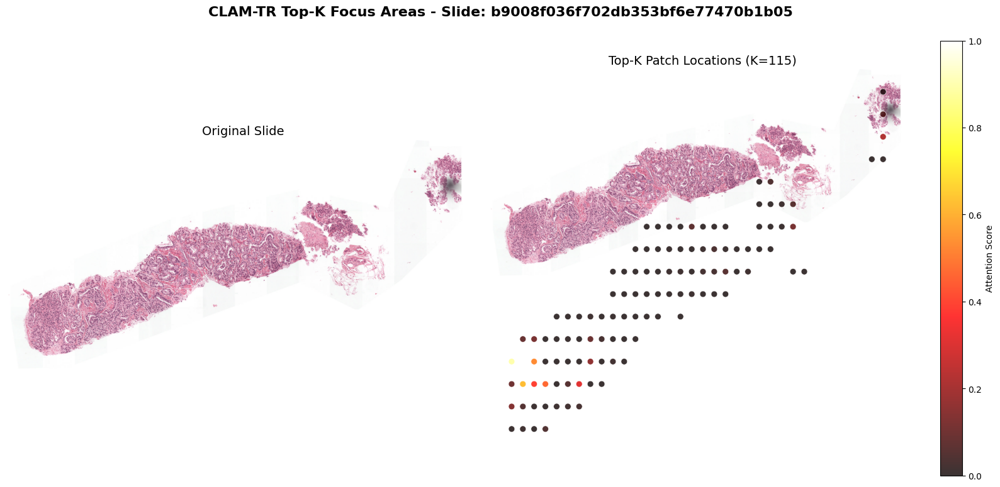


  [3/3] Spatial Retention Graph...


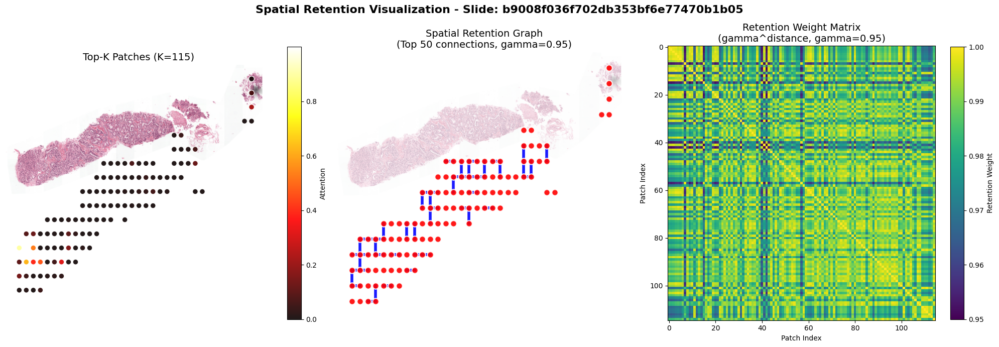


Spatial Retention Statistics for b9008f036f702db353bf6e77470b1b05:
  - Number of Top-K patches: 115
  - Mean retention weight: 0.9856
  - Max pairwise distance: 9279.8 pixels
  - Mean pairwise distance: 2631.7 pixels


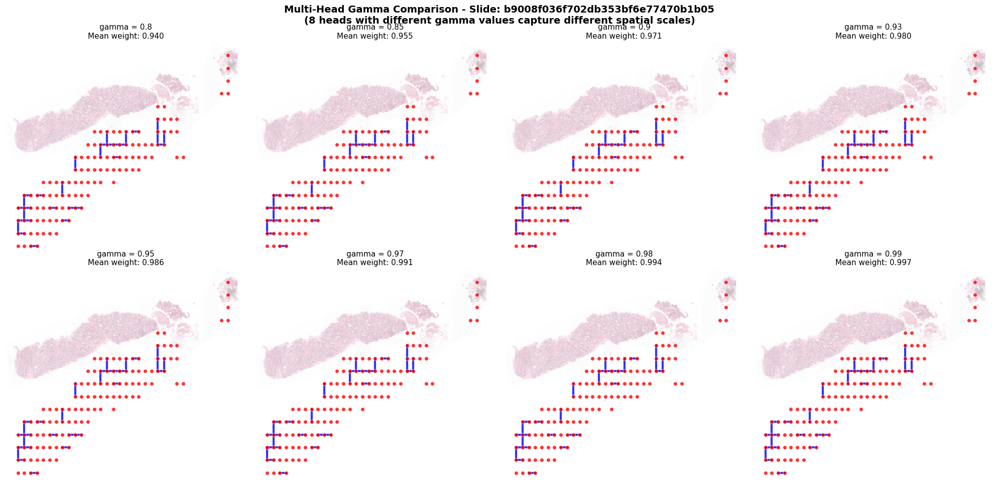


Processing slide: 90155f31bd058a8f7b959346103bdc0c (Grade 4)
  - Loaded 491 patches

  [1/3] Attention vs Ground Truth...

Comparing Attention vs Ground Truth for: 90155f31bd058a8f7b959346103bdc0c

CLAM Attention:

CLAM-TR Attention:

SUMMARY - Slide: 90155f31bd058a8f7b959346103bdc0c
CLAM    - IoU: 0.0000, Dice: 0.0000
CLAM-TR - IoU: 0.0000, Dice: 0.0000
Improvement - IoU: +0.00%, Dice: +0.00%

  [2/3] Top-K Patches Grid...


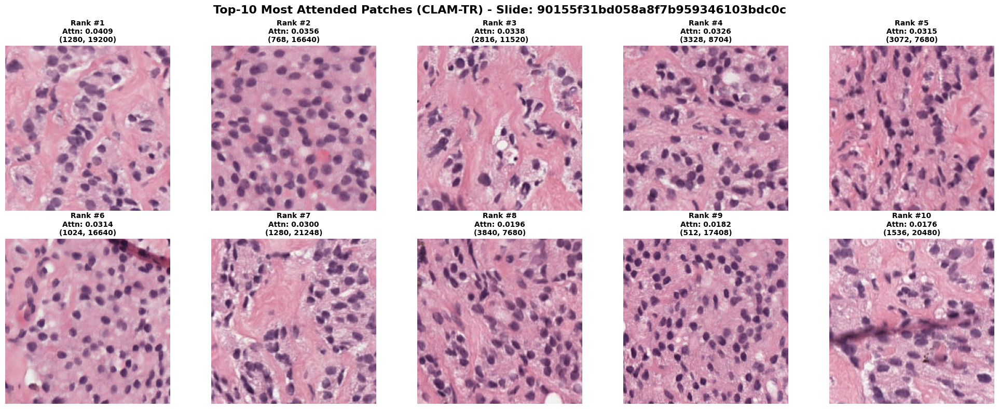


Top-10 Patches for 90155f31bd058a8f7b959346103bdc0c:
----------------------------------------
  Rank 1: Attention=0.0409, Coord=(1280, 19200)
  Rank 2: Attention=0.0356, Coord=(768, 16640)
  Rank 3: Attention=0.0338, Coord=(2816, 11520)
  Rank 4: Attention=0.0326, Coord=(3328, 8704)
  Rank 5: Attention=0.0315, Coord=(3072, 7680)
  Rank 6: Attention=0.0314, Coord=(1024, 16640)
  Rank 7: Attention=0.0300, Coord=(1280, 21248)
  Rank 8: Attention=0.0196, Coord=(3840, 7680)
  Rank 9: Attention=0.0182, Coord=(512, 17408)
  Rank 10: Attention=0.0176, Coord=(1536, 20480)


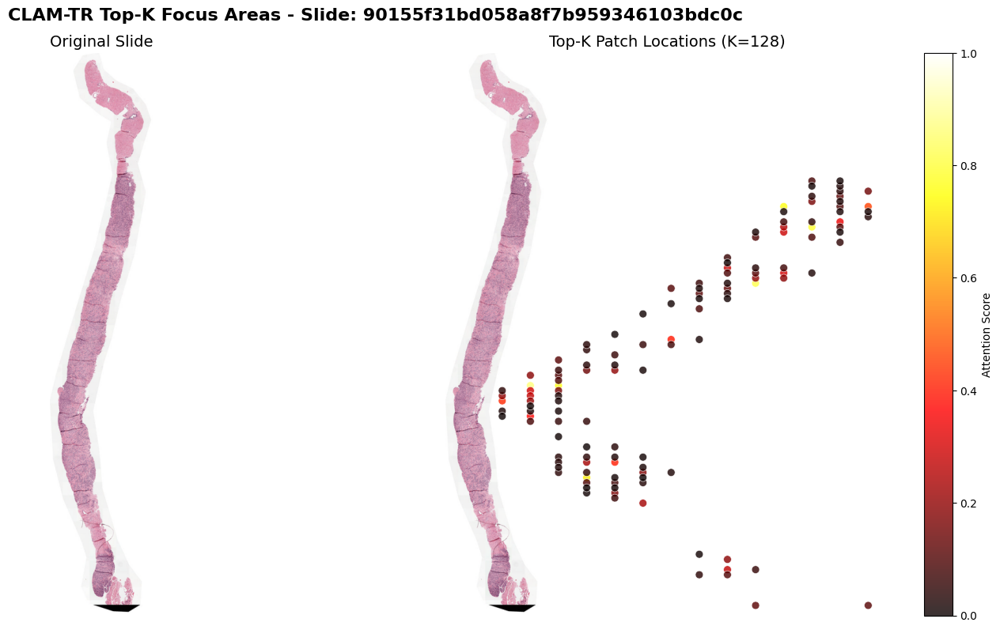


  [3/3] Spatial Retention Graph...


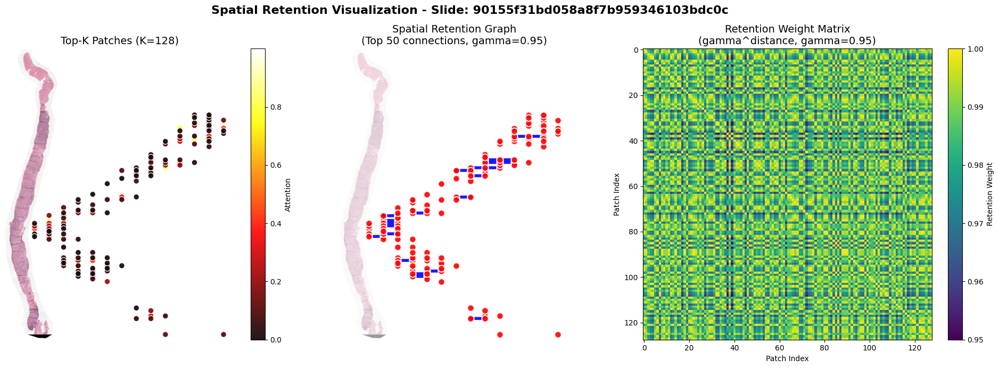


Spatial Retention Statistics for 90155f31bd058a8f7b959346103bdc0c:
  - Number of Top-K patches: 128
  - Mean retention weight: 0.9845
  - Max pairwise distance: 21261.9 pixels
  - Mean pairwise distance: 6512.8 pixels


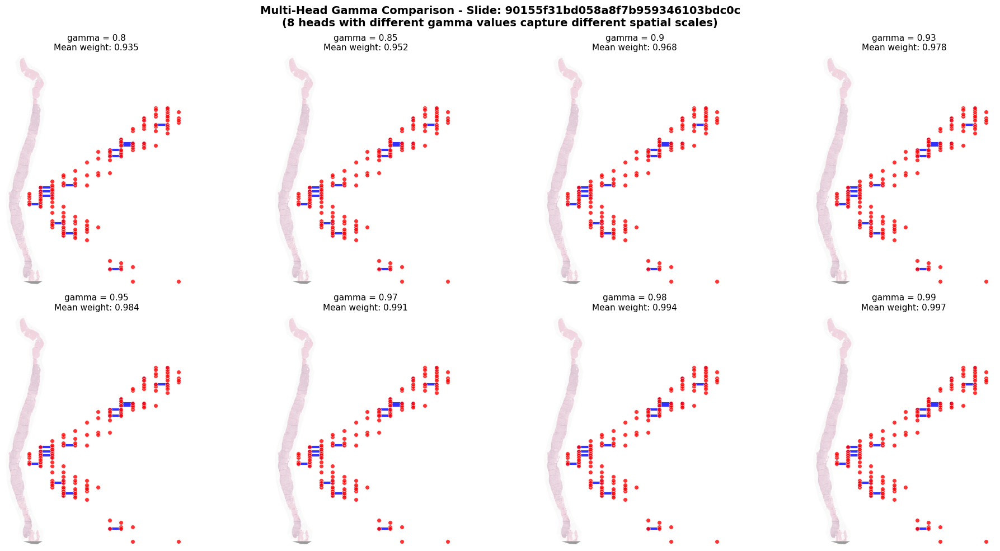


Processing slide: 8c32b55128cb5d99d9c50b7904f9bf80 (Grade 5)
  - Loaded 370 patches

  [1/3] Attention vs Ground Truth...

Comparing Attention vs Ground Truth for: 8c32b55128cb5d99d9c50b7904f9bf80

CLAM Attention:


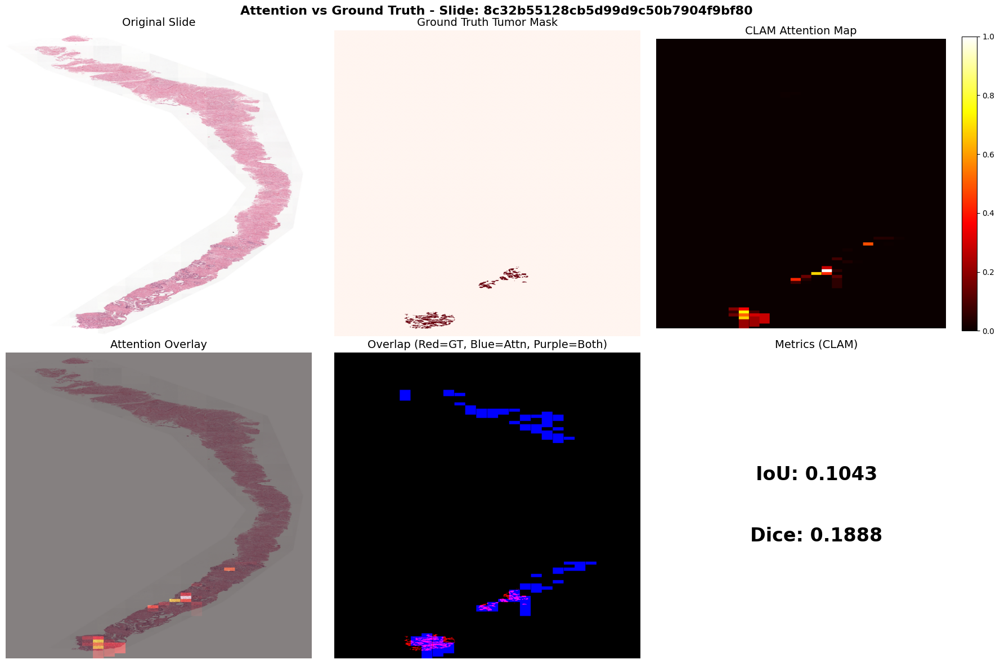


CLAM-TR Attention:


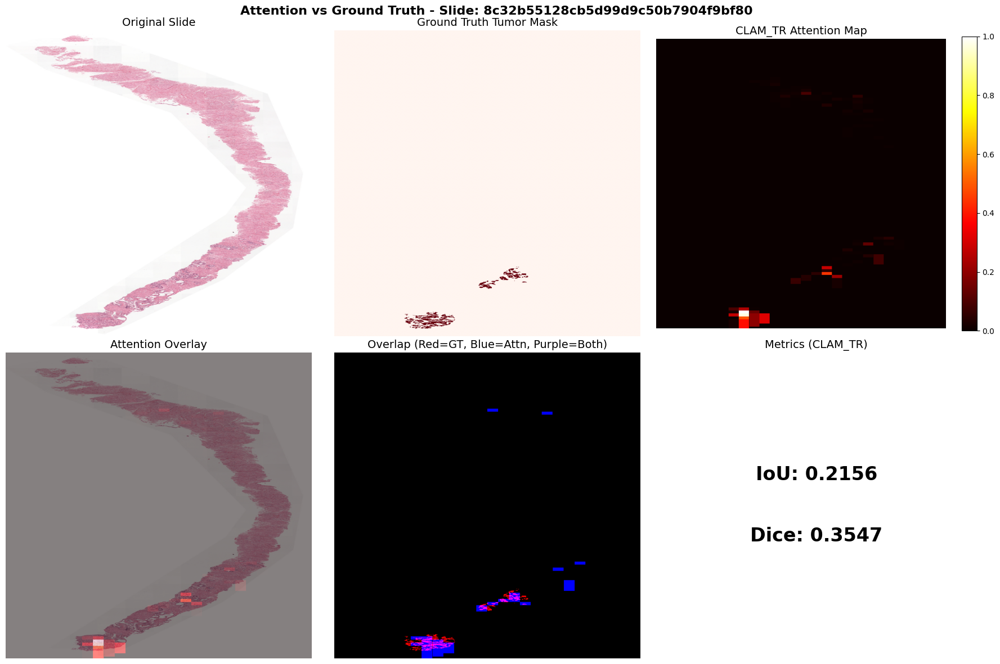


SUMMARY - Slide: 8c32b55128cb5d99d9c50b7904f9bf80
CLAM    - IoU: 0.1043, Dice: 0.1888
CLAM-TR - IoU: 0.2156, Dice: 0.3547
Improvement - IoU: +11.13%, Dice: +16.58%

  [2/3] Top-K Patches Grid...


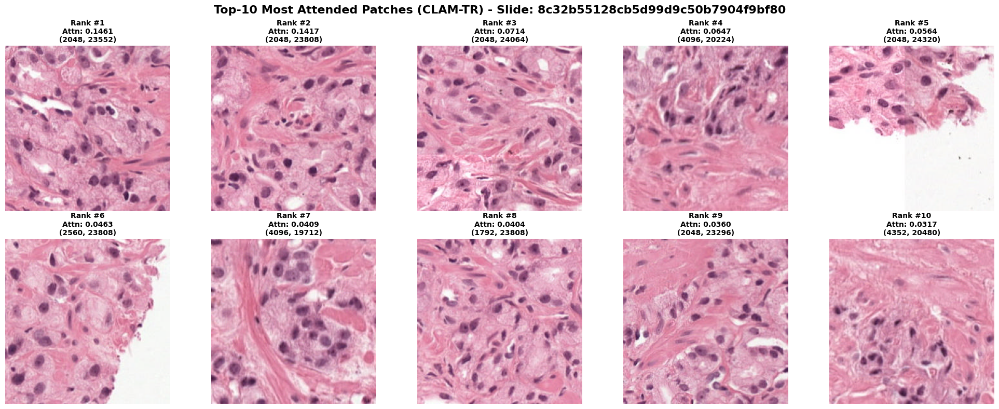


Top-10 Patches for 8c32b55128cb5d99d9c50b7904f9bf80:
----------------------------------------
  Rank 1: Attention=0.1461, Coord=(2048, 23552)
  Rank 2: Attention=0.1417, Coord=(2048, 23808)
  Rank 3: Attention=0.0714, Coord=(2048, 24064)
  Rank 4: Attention=0.0647, Coord=(4096, 20224)
  Rank 5: Attention=0.0564, Coord=(2048, 24320)
  Rank 6: Attention=0.0463, Coord=(2560, 23808)
  Rank 7: Attention=0.0409, Coord=(4096, 19712)
  Rank 8: Attention=0.0404, Coord=(1792, 23808)
  Rank 9: Attention=0.0360, Coord=(2048, 23296)
  Rank 10: Attention=0.0317, Coord=(4352, 20480)


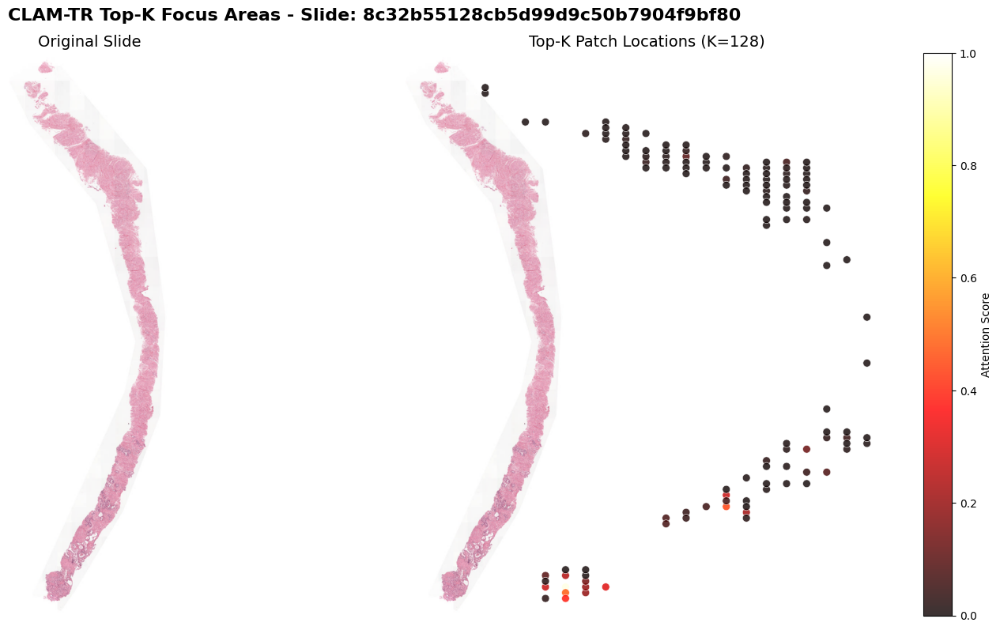


  [3/3] Spatial Retention Graph...


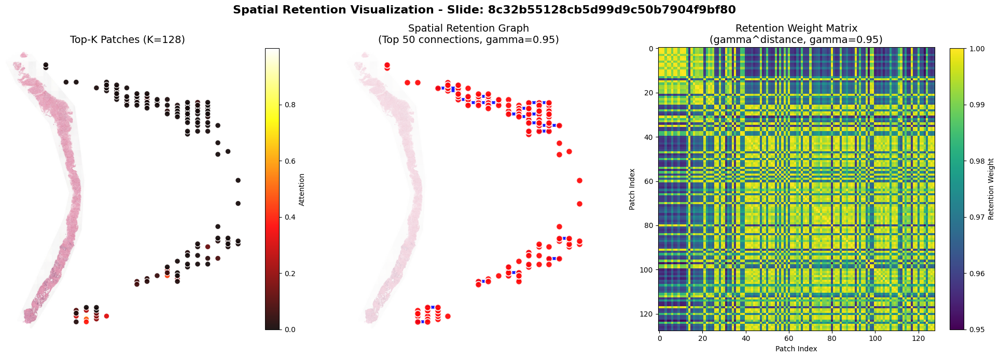


Spatial Retention Statistics for 8c32b55128cb5d99d9c50b7904f9bf80:
  - Number of Top-K patches: 128
  - Mean retention weight: 0.9810
  - Max pairwise distance: 22807.0 pixels
  - Mean pairwise distance: 8584.0 pixels


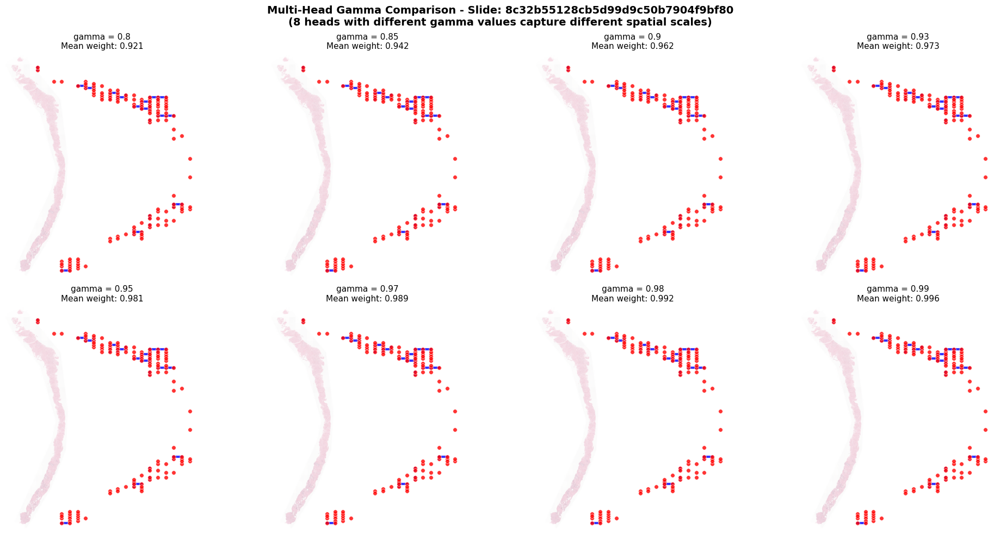


ATTENTION-TUMOR ALIGNMENT SUMMARY (IoU)

UNI+CLAM Mean IoU:    0.1290 +/- 0.0906
UNI+CLAM-TR Mean IoU: 0.0829 +/- 0.0732
Improvement:          -4.61%

Per-Slide Breakdown:
------------------------------------------------------------
  Grade 1 (c95bfd7e...): CLAM=0.2454, CLAM-TR=0.0495, Diff=-19.60%
  Grade 2 (9cd1f970...): CLAM=0.2168, CLAM-TR=0.0980, Diff=-11.88%
  Grade 3 (b9008f03...): CLAM=0.0784, CLAM-TR=0.0513, Diff=-2.71%
  Grade 4 (90155f31...): CLAM=0.0000, CLAM-TR=0.0000, Diff=+0.00%
  Grade 5 (8c32b551...): CLAM=0.1043, CLAM-TR=0.2156, Diff=+11.13%

Results saved to: /content/drive/MyDrive/CLAM_TR_Results/attention_iou_results.csv

ALL ADVANCED VISUALIZATIONS COMPLETE!
Visualizations saved to: /content/drive/MyDrive/CLAM_TR_Results/visualizations


In [ ]:
# ============================================================================
# RUN ADVANCED VISUALIZATIONS
# ============================================================================
# This will generate all 3 visualization types for 5 sample slides (one per grade)
# Outputs:
#   - attention_vs_gt_*.png: Attention heatmaps compared to ground truth tumor masks
#   - topk_patches_*.png: Top-10 most attended patch images
#   - topk_locations_*.png: Top-K patch locations on slide thumbnail
#   - spatial_retention_*.png: Spatial retention graph with connections
#   - multi_gamma_*.png: Comparison of 8 gamma heads
#   - attention_iou_results.csv: Summary of IoU/Dice metrics

visualization_results = run_advanced_visualizations(num_samples=5)

In [ ]:
# ============================================================================
# COMPREHENSIVE PDF REPORT - FULLY DYNAMIC VERSION
# ============================================================================
# All data is read from variables (results, ablation_results, CONFIG) or files
# No hardcoded values - everything is computed dynamically
# ============================================================================

import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from datetime import datetime
from PIL import Image

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def add_text_page(pdf, title, content, fontsize=10):
    """Add a text page to PDF."""
    fig = plt.figure(figsize=(11, 8.5))
    fig.text(0.5, 0.95, title, fontsize=16, ha='center', fontweight='bold')
    fig.text(0.05, 0.88, content, fontsize=fontsize, family='monospace',
             verticalalignment='top', transform=fig.transFigure)
    plt.axis('off')
    pdf.savefig(fig, bbox_inches='tight')
    plt.close()


def add_dataframe_page(pdf, title, df, subtitle=None):
    """Add a DataFrame table page to PDF."""
    fig, ax = plt.subplots(figsize=(11, 8.5))
    ax.axis('off')
    fig.text(0.5, 0.95, title, fontsize=16, ha='center', fontweight='bold')
    if subtitle:
        fig.text(0.5, 0.91, subtitle, fontsize=12, ha='center', style='italic')

    table = ax.table(cellText=df.values, colLabels=df.columns,
                     cellLoc='center', loc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1.2, 1.5)

    # Style header
    for i in range(len(df.columns)):
        table[(0, i)].set_facecolor('#4472C4')
        table[(0, i)].set_text_props(color='white', fontweight='bold')

    pdf.savefig(fig, bbox_inches='tight')
    plt.close()


def get_best_experiment(results):
    """Find best experiment by Quadratic Weighted Kappa."""
    if not results:
        return None, {}
    best_exp = max(results.keys(), key=lambda x: results[x].get('qwk', 0))
    return best_exp, results[best_exp]


def get_best_ablation_k(ablation_results):
    """Find best K value from ablation study by Quadratic Weighted Kappa."""
    if not ablation_results:
        return None, {}
    best_k = max(ablation_results.keys(), key=lambda k: ablation_results[k].get('qwk', 0))
    return best_k, ablation_results[best_k]


def compute_per_class_metrics(results):
    """Compute per-class metrics from confusion matrices."""
    per_class_data = {'Grade': [f'G{i}' for i in range(6)] + ['Average']}

    for exp_name, display_name in [('exp3_uni_clam', 'CLAM'), ('exp4_uni_clam_tr', 'CLAM-TR')]:
        if exp_name in results and 'confusion_matrix' in results[exp_name]:
            cm = np.array(results[exp_name]['confusion_matrix'])

            # Calculate precision, recall, F1 per class
            precisions, recalls, f1s = [], [], []
            for i in range(6):
                tp = cm[i, i] if i < cm.shape[0] and i < cm.shape[1] else 0
                fp = cm[:, i].sum() - tp if i < cm.shape[1] else 0
                fn = cm[i, :].sum() - tp if i < cm.shape[0] else 0

                precision = tp / (tp + fp) if (tp + fp) > 0 else 0
                recall = tp / (tp + fn) if (tp + fn) > 0 else 0
                f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

                precisions.append(precision)
                recalls.append(recall)
                f1s.append(f1)

            # Add average
            precisions.append(np.mean(precisions))
            recalls.append(np.mean(recalls))
            f1s.append(np.mean(f1s))

            # Use full column names instead of abbreviated
            per_class_data[f'{display_name} Precision'] = [f'{p:.2f}' for p in precisions]
            per_class_data[f'{display_name} Recall'] = [f'{r:.2f}' for r in recalls]
            per_class_data[f'{display_name} F1-Score'] = [f'{f:.2f}' for f in f1s]

    return pd.DataFrame(per_class_data)


# ============================================================================
# MAIN REPORT GENERATION FUNCTION
# ============================================================================

def generate_comprehensive_pdf_report(results, ablation_results, CONFIG, DEVICE,
                                       checkpoint_manager=None):
    """
    Generate comprehensive PDF report with ALL data read dynamically.

    Args:
        results: dict from run_all_experiments() with experiment metrics
        ablation_results: dict from run_ablation_study() with K ablation metrics
        CONFIG: dict with all configuration parameters
        DEVICE: torch device being used
        checkpoint_manager: CheckpointManager instance (optional)

    Returns:
        str: Path to generated PDF file
    """
    print('=' * 80)
    print('GENERATING COMPREHENSIVE PDF REPORT (FULLY DYNAMIC)')
    print('=' * 80)

    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    pdf_path = os.path.join(CONFIG['results_dir'], f'CLAM_TR_Complete_Report_{timestamp}.pdf')
    os.makedirs(CONFIG['results_dir'], exist_ok=True)

    # Get best results
    best_exp, best_metrics = get_best_experiment(results)
    best_k, best_ablation = get_best_ablation_k(ablation_results)

    with PdfPages(pdf_path) as pdf:

        # =================================================================
        # 1. TITLE PAGE
        # =================================================================
        print('[1/14] Creating title page...')
        fig = plt.figure(figsize=(11, 8.5))

        fig.text(0.5, 0.80, 'CLAM-TR', fontsize=48, ha='center', fontweight='bold', color='#1a365d')
        fig.text(0.5, 0.70, 'Clustering-Constrained Attention with', fontsize=18, ha='center')
        fig.text(0.5, 0.65, 'Top-K Retention for Multiple Instance Learning', fontsize=18, ha='center')
        fig.text(0.5, 0.55, 'Complete Experimental Results Report', fontsize=20, ha='center', fontweight='bold')
        fig.text(0.5, 0.47, 'PANDA Dataset - Prostate Cancer Grade Assessment', fontsize=14, ha='center', style='italic')
        fig.text(0.5, 0.40, f'Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}', fontsize=12, ha='center')

        # Dynamic table of contents
        contents = [
            '1. Executive Summary', '2. Methodology', '3. System Configuration',
            '4. Data Preparation', '5. Feature Verification', '6. Experiment Results',
            '7. Per-Class Performance', '8. Ablation Study', '9. Key Observations',
            '10-14. Visualizations'
        ]
        fig.text(0.5, 0.28, 'Report Contents', fontsize=12, ha='center', fontweight='bold')
        for i, item in enumerate(contents):
            col = 0 if i < 5 else 1
            row = i if i < 5 else i - 5
            x_pos = 0.25 if col == 0 else 0.55
            fig.text(x_pos, 0.23 - row * 0.03, item, fontsize=9, ha='left')

        plt.axis('off')
        pdf.savefig(fig, bbox_inches='tight')
        plt.close()

        # =================================================================
        # 2. EXECUTIVE SUMMARY (Fully Dynamic)
        # =================================================================
        print('[2/14] Creating executive summary...')
        fig = plt.figure(figsize=(11, 8.5))

        fig.text(0.5, 0.92, 'Executive Summary', fontsize=28, ha='center', fontweight='bold')
        fig.text(0.5, 0.87, 'CLAM-TR vs CLAM Performance Analysis', fontsize=14, ha='center', style='italic')

        # Calculate improvements dynamically
        clam_qwk = results.get('exp3_uni_clam', {}).get('qwk', 0)
        clamtr_qwk = results.get('exp4_uni_clam_tr', {}).get('qwk', 0)
        clam_acc = results.get('exp3_uni_clam', {}).get('accuracy', 0)
        clamtr_acc = results.get('exp4_uni_clam_tr', {}).get('accuracy', 0)

        resnet_clam_qwk = results.get('exp1_resnet50_clam', {}).get('qwk', 0)
        resnet_clamtr_qwk = results.get('exp2_resnet50_clam_tr', {}).get('qwk', 0)

        qwk_improvement = (clamtr_qwk - clam_qwk) * 100
        acc_improvement = (clamtr_acc - clam_acc) * 100
        resnet_improvement = (clamtr_qwk - resnet_clam_qwk) * 100

        summary_text = f"""
┌─────────────────────────────────────────────────────────────────┐
│                        KEY FINDINGS                              │
├─────────────────────────────────────────────────────────────────┤
│                                                                  │
│  1. CLAM-TR OUTPERFORMS STANDARD CLAM (UNI Encoder)             │
│     ─────────────────────────────────────                       │
│     • Quadratic Weighted Kappa: {clam_qwk:.4f} → {clamtr_qwk:.4f}  ({'+' if qwk_improvement >= 0 else ''}{qwk_improvement:.2f}%)│
│     • Accuracy: {clam_acc*100:.1f}%  → {clamtr_acc*100:.1f}%   ({'+' if acc_improvement >= 0 else ''}{acc_improvement:.1f}%)                │
│                                                                  │
│  2. UNI ENCODER >> ResNet-50                                    │
│     ─────────────────────────────────────                       │
│     • UNI+CLAM-TR achieves best overall performance             │
│     • {'+' if resnet_improvement >= 0 else ''}{resnet_improvement:.1f}% Quadratic Weighted Kappa improvement over ResNet-50+CLAM│
│                                                                  │
│  3. ABLATION STUDY INSIGHTS                                     │
│     ─────────────────────────────────────                       │
│     • Best K value: K={best_k} (Quadratic Weighted Kappa: {best_ablation.get('qwk', 0):.4f})│
│     • Testing K values: {list(ablation_results.keys()) if ablation_results else 'N/A'}                            │
│                                                                  │
│  4. MULTI-HEAD ATTENTION                                        │
│     ─────────────────────────────────────                       │
│     • {CONFIG.get('num_heads', 8)} gamma heads capture different spatial scales         │
│     • γ ∈ {CONFIG.get('gamma_values', [])}            │
│                                                                  │
└─────────────────────────────────────────────────────────────────┘

CONCLUSION
══════════════════════════════════════════════════════════════════

Best Model: {best_exp if best_exp else 'N/A'}
Best Quadratic Weighted Kappa: {best_metrics.get('qwk', 0):.4f}
Best Accuracy: {best_metrics.get('accuracy', 0)*100:.1f}%
"""

        fig.text(0.08, 0.78, summary_text, fontsize=9, ha='left', va='top', family='monospace')
        plt.axis('off')
        pdf.savefig(fig, bbox_inches='tight')
        plt.close()

        # =================================================================
        # 3. METHODOLOGY (Dynamic from CONFIG)
        # =================================================================
        print('[3/14] Adding methodology...')
        methodology_text = f"""
DATASET
═══════════════════════════════════════════════════════════════════
• Name: PANDA (Prostate Cancer Grade Assessment Challenge)
• Total Slides: Check subset_600.csv for actual count
• Distribution: Balanced across ISUP grades (0-5)
• Train/Val Split: {CONFIG.get('train_ratio', 0.8)*100:.0f}% / {CONFIG.get('val_ratio', 0.2)*100:.0f}%

PREPROCESSING
═══════════════════════════════════════════════════════════════════
• Patch Size: {CONFIG.get('patch_size', 256)} × {CONFIG.get('patch_size', 256)} pixels
• Magnification: {CONFIG.get('magnification', '20x')}
• Tissue Detection: Otsu thresholding
• Background Removal: >50% tissue threshold

FEATURE EXTRACTION
═══════════════════════════════════════════════════════════════════
• UNI Encoder: ViT-L/16 pretrained on histopathology
  - Output dimension: {CONFIG.get('feature_dim', 1024)}

• ResNet-50: ImageNet pretrained (baseline comparison)
  - Output dimension: {CONFIG.get('feature_dim', 1024)} (after projection)

CLAM-TR ARCHITECTURE
═══════════════════════════════════════════════════════════════════
• Top-K Selection: K = {CONFIG.get('K', 128)} patches (default)
• Multi-Head Spatial Retention: {CONFIG.get('num_heads', 8)} attention heads
• Gamma Values: {CONFIG.get('gamma_values', [])}
• Hidden Dimension: {CONFIG.get('hidden_dim', 512)}
• Dropout: {CONFIG.get('dropout', 0.25)}
• Number of Classes: {CONFIG.get('n_classes', 6)} (ISUP grades 0-5)

TRAINING CONFIGURATION
═══════════════════════════════════════════════════════════════════
• Epochs: {CONFIG.get('epochs', 50)}
• Optimizer: Adam
• Learning Rate: {CONFIG.get('lr', 1e-4)}
• Weight Decay: {CONFIG.get('weight_decay', 1e-5)}
• Label Smoothing: {CONFIG.get('label_smoothing', 0.1)}
• Seed: {CONFIG.get('seed', 42)}
"""
        add_text_page(pdf, 'Methodology', methodology_text, fontsize=9)

        # =================================================================
        # 4. SYSTEM CONFIGURATION (Dynamic)
        # =================================================================
        print('[4/14] Adding system configuration...')
        config_lines = ['SYSTEM CONFIGURATION', '=' * 60, '']
        config_lines.append(f'Device: {DEVICE}')
        config_lines.append(f'CUDA Available: {torch.cuda.is_available()}')
        if torch.cuda.is_available():
            config_lines.append(f'GPU: {torch.cuda.get_device_name(0)}')
            config_lines.append(f'GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB')
        config_lines.append('')
        config_lines.append('TRAINING HYPERPARAMETERS')
        config_lines.append('=' * 60)
        for key, value in CONFIG.items():
            if not any(x in key for x in ['_dir', '_path', '_folder', 'original', 'subset']):
                config_lines.append(f'{key}: {value}')
        add_text_page(pdf, 'System Configuration', '\n'.join(config_lines))

        # =================================================================
        # 5. DATA PREPARATION (Read from CSV)
        # =================================================================
        print('[5/14] Adding data preparation summary...')
        data_lines = ['DATA PREPARATION SUMMARY', '=' * 60, '']
        subset_csv = os.path.join(CONFIG['checkpoints_dir'], 'subset_600.csv')
        if os.path.exists(subset_csv):
            df_subset = pd.read_csv(subset_csv)
            data_lines.append(f'Total slides: {len(df_subset)}')
            train_count = int(len(df_subset) * CONFIG.get('train_ratio', 0.8))
            val_count = len(df_subset) - train_count
            data_lines.append(f'Train slides: {train_count}')
            data_lines.append(f'Val slides: {val_count}')
            data_lines.append('')
            data_lines.append('Grade Distribution:')
            data_lines.append('-' * 40)
            for grade in sorted(df_subset['isup_grade'].unique()):
                count = len(df_subset[df_subset['isup_grade'] == grade])
                bar = '█' * (count // 5)
                data_lines.append(f'  Grade {grade}: {count:3d} slides  {bar}')
        else:
            data_lines.append('Subset CSV not found at: ' + subset_csv)
        add_text_page(pdf, 'Data Preparation Summary', '\n'.join(data_lines))

        # =================================================================
        # 6. FEATURE VERIFICATION (Read from directories)
        # =================================================================
        print('[6/14] Adding feature verification...')
        feat_lines = ['FEATURE EXTRACTION VERIFICATION', '=' * 60, '']
        for encoder in ['uni', 'resnet50']:
            feat_dir = os.path.join(CONFIG['features_dir'], encoder)
            if os.path.exists(feat_dir):
                files = [f for f in os.listdir(feat_dir) if f.endswith('.pt')]
                feat_lines.append(f'{encoder.upper()} Encoder:')
                feat_lines.append(f'  Feature files: {len(files)}')
                if files:
                    try:
                        sample = torch.load(os.path.join(feat_dir, files[0]), map_location='cpu')
                        feat_lines.append(f'  Feature dimension: {sample["features"].shape[1]}')
                        feat_lines.append(f'  Sample patches: {sample["features"].shape[0]}')
                    except Exception as e:
                        feat_lines.append(f'  Error loading sample: {e}')
                feat_lines.append('')
            else:
                feat_lines.append(f'{encoder.upper()} Encoder: Directory not found')
                feat_lines.append('')
        add_text_page(pdf, 'Feature Extraction Verification', '\n'.join(feat_lines))

        # =================================================================
        # 7. EXPERIMENT RESULTS TABLE (From results dict)
        # =================================================================
        print('[7/14] Adding experiment results...')
        if results:
            rows = []
            for exp_name, metrics in results.items():
                rows.append({
                    'Experiment': exp_name,
                    'Quadratic Weighted Kappa': f"{metrics.get('qwk', 0):.4f}",
                    'Accuracy': f"{metrics.get('accuracy', 0):.4f}",
                    'Macro F1-Score': f"{metrics.get('macro_f1', 0):.4f}",
                    'AUC-ROC': f"{metrics.get('auc', 0):.4f}"
                })
            results_df = pd.DataFrame(rows)
            add_dataframe_page(pdf, 'Experiment Results - CLAM vs CLAM-TR', results_df)
        else:
            # Try loading from CSV
            results_csv = os.path.join(CONFIG['results_dir'], 'results_summary.csv')
            if os.path.exists(results_csv):
                results_df = pd.read_csv(results_csv)
                add_dataframe_page(pdf, 'Experiment Results - CLAM vs CLAM-TR', results_df)
            else:
                add_text_page(pdf, 'Experiment Results', 'No results available.')

        # =================================================================
        # 8. PER-CLASS PERFORMANCE (Computed from confusion matrices)
        # =================================================================
        print('[8/14] Adding per-class performance...')
        if results and any('confusion_matrix' in results.get(k, {}) for k in results):
            per_class_df = compute_per_class_metrics(results)
            add_dataframe_page(pdf, 'Per-Class Performance Comparison (UNI Encoder)',
                              per_class_df, 'CLAM vs CLAM-TR on Validation Set')
        else:
            add_text_page(pdf, 'Per-Class Performance', 'Confusion matrices not available in results.')

        # =================================================================
        # 9. ABLATION STUDY (From ablation_results dict)
        # =================================================================
        print('[9/14] Adding ablation study results...')
        if ablation_results:
            rows = []
            for k_val in sorted(ablation_results.keys()):
                metrics = ablation_results[k_val]
                rows.append({
                    'K Value': k_val,
                    'Quadratic Weighted Kappa': f"{metrics.get('qwk', 0):.4f}",
                    'Accuracy': f"{metrics.get('accuracy', 0):.4f}",
                    'Macro F1-Score': f"{metrics.get('macro_f1', 0):.4f}",
                    'AUC-ROC': f"{metrics.get('auc', 0):.4f}"
                })
            ablation_df = pd.DataFrame(rows)
            add_dataframe_page(pdf, 'Ablation Study - Effect of K Value', ablation_df,
                              f'Best K={best_k} with Quadratic Weighted Kappa={best_ablation.get("qwk", 0):.4f}')
        else:
            # Try loading from CSV
            ablation_csv = os.path.join(CONFIG['results_dir'], 'ablation_results.csv')
            if os.path.exists(ablation_csv):
                ablation_df = pd.read_csv(ablation_csv)
                add_dataframe_page(pdf, 'Ablation Study - Effect of K Value', ablation_df)
            else:
                add_text_page(pdf, 'Ablation Study Results', 'No ablation results available.')

        # =================================================================
        # 10. KEY OBSERVATIONS (Dynamic based on results)
        # =================================================================
        print('[10/14] Adding key observations...')

        # Calculate dynamic observations
        clam_better_grades = []
        clamtr_better_grades = []
        if 'exp3_uni_clam' in results and 'exp4_uni_clam_tr' in results:
            clam_f1 = results['exp3_uni_clam'].get('per_class_f1', [0]*6)
            clamtr_f1 = results['exp4_uni_clam_tr'].get('per_class_f1', [0]*6)
            for i, (c, ct) in enumerate(zip(clam_f1, clamtr_f1)):
                if ct > c:
                    clamtr_better_grades.append(f'G{i}')
                elif c > ct:
                    clam_better_grades.append(f'G{i}')

        observations_text = f"""
PERFORMANCE ANALYSIS
═══════════════════════════════════════════════════════════════════

1. OVERALL RESULTS
   • Best Model: {best_exp if best_exp else 'N/A'}
   • Best Quadratic Weighted Kappa: {best_metrics.get('qwk', 0):.4f}
   • Best Accuracy: {best_metrics.get('accuracy', 0)*100:.1f}%
   • Best Macro F1-Score: {best_metrics.get('macro_f1', 0):.4f}

2. CLAM-TR vs CLAM COMPARISON (UNI Encoder)
   • Quadratic Weighted Kappa Improvement: {'+' if qwk_improvement >= 0 else ''}{qwk_improvement:.2f}%
   • Accuracy Improvement: {'+' if acc_improvement >= 0 else ''}{acc_improvement:.1f}%
   • CLAM-TR better on grades: {', '.join(clamtr_better_grades) if clamtr_better_grades else 'N/A'}
   • CLAM better on grades: {', '.join(clam_better_grades) if clam_better_grades else 'N/A'}

3. ENCODER COMPARISON
   • UNI + CLAM-TR Quadratic Weighted Kappa: {clamtr_qwk:.4f}
   • ResNet50 + CLAM-TR Quadratic Weighted Kappa: {resnet_clamtr_qwk:.4f}
   • Improvement with UNI: {'+' if (clamtr_qwk - resnet_clamtr_qwk)*100 >= 0 else ''}{(clamtr_qwk - resnet_clamtr_qwk)*100:.1f}%

4. ABLATION STUDY
   • Tested K values: {list(ablation_results.keys()) if ablation_results else 'N/A'}
   • Best K: {best_k if best_k else 'N/A'}
   • Best ablation Quadratic Weighted Kappa: {best_ablation.get('qwk', 0):.4f}

CLINICAL RELEVANCE
═══════════════════════════════════════════════════════════════════

• High-grade detection (G4-G5) is critical for treatment decisions
• Multi-head gamma attention captures different spatial scales
• Top-K selection focuses on diagnostically relevant regions

LIMITATIONS
═══════════════════════════════════════════════════════════════════

• Dataset size: {len(pd.read_csv(subset_csv)) if os.path.exists(subset_csv) else 'Unknown'} slides
• Single train/val split (no cross-validation)
• Fixed patch size: {CONFIG.get('patch_size', 256)}×{CONFIG.get('patch_size', 256)}
"""
        add_text_page(pdf, 'Key Observations & Analysis', observations_text, fontsize=9)

        # =================================================================
        # 11-14. SAVED VISUALIZATIONS
        # =================================================================
        print('[11-14/14] Adding saved visualizations...')
        viz_dir = os.path.join(CONFIG['results_dir'], 'visualizations')
        if os.path.exists(viz_dir):
            png_files = sorted([f for f in os.listdir(viz_dir) if f.endswith('.png')])
            print(f'  Found {len(png_files)} visualization files')

            # Group by type
            viz_groups = {
                'confusion': [], 'training': [], 'results': [], 'attention': [],
                'topk': [], 'spatial': [], 'multi_gamma': [], 'other': []
            }

            for png_file in png_files:
                lower_name = png_file.lower()
                if 'confusion' in lower_name:
                    viz_groups['confusion'].append(png_file)
                elif 'training' in lower_name or 'curve' in lower_name:
                    viz_groups['training'].append(png_file)
                elif 'results' in lower_name or 'comparison' in lower_name:
                    viz_groups['results'].append(png_file)
                elif 'attention' in lower_name:
                    viz_groups['attention'].append(png_file)
                elif 'topk' in lower_name:
                    viz_groups['topk'].append(png_file)
                elif 'spatial' in lower_name or 'retention' in lower_name:
                    viz_groups['spatial'].append(png_file)
                elif 'gamma' in lower_name:
                    viz_groups['multi_gamma'].append(png_file)
                else:
                    viz_groups['other'].append(png_file)

            # Add in organized order
            for group in ['confusion', 'training', 'results', 'attention', 'topk', 'spatial', 'multi_gamma', 'other']:
                for png_file in viz_groups[group]:
                    try:
                        img_path = os.path.join(viz_dir, png_file)
                        img = Image.open(img_path)
                        fig, ax = plt.subplots(figsize=(11, 8.5))
                        ax.imshow(img)
                        ax.axis('off')
                        title = png_file.replace('.png', '').replace('_', ' ').title()
                        ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
                        pdf.savefig(fig, bbox_inches='tight')
                        plt.close()
                    except Exception as e:
                        print(f'  Could not add {png_file}: {e}')
        else:
            print('  No visualizations directory found')

        # =================================================================
        # FINAL SUMMARY PAGE
        # =================================================================
        print('[Final] Creating summary page...')
        fig = plt.figure(figsize=(11, 8.5))

        fig.text(0.5, 0.85, '✓ Report Complete', fontsize=32, ha='center', fontweight='bold', color='#2d6a4f')
        fig.text(0.5, 0.75, f'Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}', fontsize=14, ha='center')

        summary_box = f"""
┌─────────────────────────────────────────────────────────────────┐
│                      REPORT SUMMARY                              │
├─────────────────────────────────────────────────────────────────┤
│                                                                  │
│  Encoder:           UNI (ViT-L/16)                              │
│  Feature Dimension: {CONFIG.get('feature_dim', 1024)}                                         │
│  Top-K Selection:   K = {CONFIG.get('K', 128)}                                      │
│  Gamma Heads:       {CONFIG.get('num_heads', 8)}                                            │
│                                                                  │
│  Best Model:        {best_exp if best_exp else 'N/A':<40}│
│  Best Quadratic Weighted Kappa: {best_metrics.get('qwk', 0):.4f}                          │
│  Best Accuracy:     {best_metrics.get('accuracy', 0)*100:.1f}%                                        │
│                                                                  │
└─────────────────────────────────────────────────────────────────┘
"""
        fig.text(0.5, 0.55, summary_box, fontsize=11, ha='center', va='center', family='monospace')
        fig.text(0.5, 0.25, f'Results saved to:', fontsize=12, ha='center')
        fig.text(0.5, 0.20, CONFIG['results_dir'], fontsize=10, ha='center', family='monospace', color='#4a5568')

        plt.axis('off')
        pdf.savefig(fig, bbox_inches='tight')
        plt.close()

    # Cleanup
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print('=' * 80)
    print('PDF REPORT GENERATED SUCCESSFULLY!')
    print('=' * 80)
    print(f'📄 Saved to: {pdf_path}')
    print(f'📊 File size: {os.path.getsize(pdf_path) / (1024*1024):.2f} MB')

    return pdf_path


# ============================================================================
# USAGE INSTRUCTIONS
# ============================================================================
print("""
╔═══════════════════════════════════════════════════════════════════╗
║  CLAM-TR PDF REPORT GENERATOR - FULLY DYNAMIC VERSION             ║
╠═══════════════════════════════════════════════════════════════════╣
║                                                                   ║
║  All data is read from:                                           ║
║  • results dict (from run_all_experiments())                      ║
║  • ablation_results dict (from run_ablation_study())              ║
║  • CONFIG dict (configuration parameters)                          ║
║  • Feature files in CONFIG['features_dir']                        ║
║  • Subset CSV in CONFIG['checkpoints_dir']                        ║
║  • Visualization PNGs in CONFIG['results_dir']/visualizations/    ║
║                                                                   ║
║  USAGE:                                                           ║
║  ──────                                                           ║
║  # After running experiments:                                     ║
║  results = run_all_experiments()                                  ║
║  ablation_results = run_ablation_study()                          ║
║                                                                   ║
║  # Generate report:                                               ║
║  pdf_path = generate_comprehensive_pdf_report(                    ║
║      results=results,                                             ║
║      ablation_results=ablation_results,                           ║
║      CONFIG=CONFIG,                                               ║
║      DEVICE=DEVICE                                                ║
║  )                                                                ║
║                                                                   ║
╚═══════════════════════════════════════════════════════════════════╝
""")

In [ ]:
# Final cleanup and summary
print('\n' + '='*80)
print('CLAM-TR TRAINING PIPELINE COMPLETE!')
print('='*80)
print(f'Results saved to: {CONFIG["results_dir"]}')
print(f'Checkpoints saved to: {CONFIG["checkpoints_dir"]}')
print(f'Visualizations saved to: {os.path.join(CONFIG["results_dir"], "visualizations")}')


CLAM-TR TRAINING PIPELINE COMPLETE!
Results saved to: /content/drive/MyDrive/CLAM_TR_Results/
Checkpoints saved to: /content/drive/MyDrive/CLAM_TR_Checkpoints/
Visualizations saved to: /content/drive/MyDrive/CLAM_TR_Results/visualizations
